# 03. 정제 — 전체 11단계 중 3단계

빠진 값과 이상해 보이는 값에 원인을 붙인 뒤, 뺄지 채울지 남길지 정하는 단계입니다. 원인 없이 지우지 않습니다. 2단계와 4단계에서 데이터에 문제 셋이 나왔고 여기서 하나씩 정합니다. 2024년 2월 29일(API에 그날이 없음)을 뺀다는 것은 09-12에 이미 정했습니다.

- **물음 1** — 2024년 8월과 2026년 5월을 어떻게 할까
- **물음 2** — 태양광 설비용량을 어떻게 할까
- **물음 3** — 2023년에 상자 밖으로 나온 점 22개를 어떻게 할까

**이 노트북이 도는 순서.** 맨 위 준비 셀 두 개를 먼저 돌립니다. 세 물음이 다 이 두 셀에서 만든 표를 씁니다. 그다음부터는 **셀 하나 → 그 아래 「✍️ 내 생각」 칸 → 그 아래 클로드 답 칸**이 되풀이됩니다. 셀을 돌리고 보이는 것을 적으시면, 제가 그 아래 새 칸에서 맞게 읽으신 것과 다르게 읽으신 것을 갈라 적습니다. 물음 하나의 마지막 셀 아래에서 그 물음을 어떻게 할지 정합니다.

**2026-09-19에 이 노트북을 고친 내용.** 09-17에 만들 때는 2단계와 칸 모양이 달랐습니다. 2단계에서 쓴 모양으로 맞췄습니다 — 셀 하나마다 적는 칸을 두고, 정할 것에는 번호를 붙이고, 제 답은 창주 님 칸 안에 섞지 않고 바로 아래 새 칸에 적습니다. 2026년 5월을 보는 셀 셋(1-나·1-다·1-라)을 새로 넣었고, 출력이 30줄을 넘어 화면에서 접히던 셀 셋(옛 1-가·2-가·3-가)을 나눠 담았습니다.

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 |
| 3 | 정제 ◀ 이 노트북 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 |
| 6 | 분석계획 |
| 7 | 모델링과 검정 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 이 과제만의 물음 — 2026년은 평소와 얼마나 달랐나 |
| 10 | 그 답을 숫자로 내기 |
| 11 | 결론 |

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.

옛 이름 대응 — 묶음 1 = 2단계 · 묶음 2 = 4단계 · 묶음 3a = 3단계 · 묶음 3b = 5·6단계 · 묶음 4·5 = 7·8단계 · 묶음 6 = 9·10단계 · 묶음 7 = 11단계. 옛 파일 `01_eda`는 지금 `02_데이터보기`와 `04_탐색`으로, `02_model`은 `03_정제`·`05_파생변수`·`06_분석계획`으로 나뉘었습니다. 옛 칸 본문에 나오는 「묶음 N」은 이 표로 바꿔 읽으시면 됩니다.

# 준비 셀 둘

아래 두 셀을 먼저 돌립니다. 물음 셋이 다 이 두 셀에서 만든 표를 씁니다. 준비 ①은 파일을 읽는 함수를 만들고, 준비 ②는 세 해를 한 표로 붙입니다. 결과를 거의 안 찍으므로 적는 칸을 두지 않았습니다.

In [99]:
# 3단계 정제 · 준비 ①
import os                                     # 폴더·파일 경로를 다루는 기본 모듈
import numpy as np                            # 평균·제곱근 같은 숫자 계산
import pandas as pd                           # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt               # 그림 그리는 라이브러리
plt.rcParams["font.family"] = "AppleGothic"   # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False    # 마이너스 부호가 깨지지 않게
pd.set_option("display.width", 200)           # 표가 줄바꿈 없이 넓게 보이게
pd.set_option("display.max_columns", 50)      # 열이 많아도 생략하지 않게
pd.set_option("display.unicode.east_asian_width", True)   # 한글 열 이름을 두 칸으로 세어 표가 어긋나지 않게

ROOT = os.getcwd()                            # 지금 폴더(보통 notebooks/)에서 시작해
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)              # data 폴더가 보일 때까지 위로 = 프로젝트 루트
RAW = os.path.join(ROOT, "data", "raw")       # 원자료 폴더

버린날 = []                                     # 192행이 아니어서 버린 날짜를 담아 둘 목록

def load_kpx(year):                                                     # KPX 연간 파일 한 해를 읽어 열 이름을 통일한다
    folder = os.path.join(RAW, "kpx")
    name = [f for f in os.listdir(folder) if f"{year}1231" in f][0]      # 파일명에 20231231 같은 기준일이 들어 있다
    df = pd.read_csv(os.path.join(folder, name), encoding="utf-8-sig")   # 맨 앞 BOM이 있는 utf-8
    df.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]              # 해마다 열 이름이 달라서 순서로 통일한다
    df["fuel"] = df["fuel"].str.strip()                                  # 연료 이름 앞뒤 공백 제거
    df["ts"] = pd.to_datetime(df["date"]) + pd.to_timedelta(df["hour"].astype(int) - 1, unit="h")  # 1~24시를 0~23시 시각으로
    return df

def pick(df, fuel, col, newname):               # 연료 하나에서 '시각 + 값' 두 열만 떼 온다
    d = df[df["fuel"] == fuel]                  # 그 연료의 행만 남긴다
    return d[["ts", col]].rename(columns={col: newname})    # 열 이름을 알아보기 쉽게 바꾼다

def load_api_year(year):                        # API 일별 파일을 한 해치 모아 붙인다
    folder = os.path.join(RAW, "api")
    files = [f for f in sorted(os.listdir(folder))                       # 파일 이름이 20240102.csv 꼴이라
             if f.startswith(str(year)) and f.endswith(".csv")]          # 앞 네 자리로 그 해만 고른다
    parts = []
    for f in files:
        q = os.path.join(folder, f)
        if os.path.getsize(q) < 100:            # 100바이트 미만 = 0행 파일(2024-02-29 — API에 그날이 없다)
            continue                            # 건너뛴다
        one = pd.read_csv(q, encoding="utf-8-sig")   # 하루치를 읽는다
        if len(one) != 192:                     # 정상은 연료 8종 × 24시간 = 192행이다
            버린날.append(f[:8])                 # 192행이 아니면 날짜만 적어 두고
            continue                            # 그 하루는 쓰지 않는다 (2024년 8월 1일부터 31일까지가 여기 걸린다)
        parts.append(one)                       # 정상인 하루만 모은다
    a = pd.concat(parts, ignore_index=True)     # 하루치 파일들을 위아래로 붙인다
    a = a.rename(columns={"fuelTpCd": "fuel"})  # API의 연료 열 이름을 연간 파일과 같게
    a["ts"] = pd.to_datetime(a["tradeYmd"].astype(str)) + pd.to_timedelta(a["tradeNo"].astype(int) - 1, unit="h")
    return a                                    # tradeNo가 1~24시라 연간 파일과 같은 방식으로 0~23시로

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다


프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [100]:
# 3단계 정제 · 준비 ②
frames = []
for y in (2023, 2025):                          # 이 두 해는 연간 파일 하나에 LNG·원자력·태양광이 다 있다
    k = load_kpx(y)
    t = pick(k, "LNG", "mwh", "lng_mwh") \
        .merge(pick(k, "원자력", "mwh", "nuke_mwh"), on="ts", how="left") \
        .merge(pick(k, "태양광", "cap_mw", "solar_cap_mw"), on="ts", how="left")   # 태양광은 발전량이 아니라 설비용량(MW)
    frames.append(t)

k24 = load_kpx(2024)                            # 2024 연간 파일 — 태양광 설비용량은 여기 있다
a24 = load_api_year(2024)                       # 2024 API — LNG·원자력은 여기 있다(API에는 설비용량 열이 없다)
t24 = pick(a24, "LNG", "amgo", "lng_mwh") \
      .merge(pick(a24, "원자력", "amgo", "nuke_mwh"), on="ts", how="left") \
      .merge(pick(k24, "태양광", "cap_mw", "solar_cap_mw"), on="ts", how="left")
frames.append(t24)

tbl = pd.concat(frames, ignore_index=True).sort_values("ts").reset_index(drop=True)  # 세 해를 시간순으로 한 장에

asos_dir = os.path.join(RAW, "asos")            # 기상(ASOS 서울 108)을 같은 시각에 붙인다
asos = pd.concat([pd.read_csv(os.path.join(asos_dir, f), encoding="utf-8-sig")
                  for f in sorted(os.listdir(asos_dir)) if f.endswith(".csv")], ignore_index=True)
asos["ts"] = pd.to_datetime(asos["tm"])         # '2023-01-01 00:00' 글자를 시각으로
tbl = tbl.merge(asos[["ts", "ta", "hm", "icsr"]], on="ts", how="left")   # 기온·습도·일사
tbl["icsr"] = tbl["icsr"].fillna(0)             # 일사는 해가 없을 때 비는 것이 정상이므로 0으로

tbl["year"] = tbl["ts"].dt.year                 # 달력에서 만드는 파생변수 — 2023 / 2024 / 2025
tbl["month"] = tbl["ts"].dt.month               # 1~12월
tbl["hour24"] = tbl["ts"].dt.hour               # 0~23시
tbl["dow"] = tbl["ts"].dt.dayofweek             # 요일 0=월 … 6=일
tbl["is_weekend"] = (tbl["dow"] >= 5).astype(int)   # 토·일이면 1

if 버린날:                                       # 버린 날이 있으면 먼저 알린다
    print(f"192행이 아니어서 버린 날 {len(버린날)}일: {버린날[0]} ~ {버린날[-1]}")
    print("  2024년 8월은 API에 원자력·무연탄·유전이 빠지고 남은 연료의 값도 잘못 들어 있다(2026-09-15 재요청으로 확인).\n")
print("표 모양 (행, 열):", tbl.shape)
print("\n해별 행 수와 기간")
print(tbl.groupby("year").agg(행수=("ts", "size"), 시작=("ts", "min"), 끝=("ts", "max")))
print("\n붙이다가 빈 칸이 생겼는지 — 전부 0이어야 같은 시각끼리 빠짐없이 붙은 것이다")
print(tbl.isna().sum().to_string())

학습해 = [2023, 2024]   # 학습에 쓸 해. 2024년은 8월 한 달과 2월 29일이 빠져 334일이다
train = tbl[tbl["year"].isin(학습해)]            # 학습 기간 — 재료를 뽑는 데 쓴다
valid = tbl[tbl["year"] == 2025]                # 채점 기간 — 2025

print("\n학습 기간", 학습해, "—", len(train), "행 / 채점 2025 —", len(valid), "행")


192행이 아니어서 버린 날 31일: 20240801 ~ 20240831
  2024년 8월은 API에 원자력·무연탄·유전이 빠지고 남은 연료의 값도 잘못 들어 있다(2026-09-15 재요청으로 확인).

표 모양 (행, 열): (25536, 12)

해별 행 수와 기간
      행수       시작                  끝
year                                     
2023  8760 2023-01-01 2023-12-31 23:00:00
2024  8016 2024-01-01 2024-12-31 23:00:00
2025  8760 2025-01-01 2025-12-31 23:00:00

붙이다가 빈 칸이 생겼는지 — 전부 0이어야 같은 시각끼리 빠짐없이 붙은 것이다
ts              0
lng_mwh         0
nuke_mwh        0
solar_cap_mw    0
ta              0
hm              0
icsr            0
year            0
month           0
hour24          0
dow             0
is_weekend      0

학습 기간 [2023, 2024] — 16776 행 / 채점 2025 — 8760 행


# 물음 1 — 2024년 8월과 2026년 5월을 어떻게 할까

**적을 곳 셋입니다 — 「1-가」·「1-나」·「1-다 · 1-라」 아래에 있는 「✍️ 내 답변」 칸입니다.** 마지막 것에는 번호 붙은 질문이 셋 더 있습니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.

> 「3개의 데이터가 빠져있으니까 전체적인 데이터를 비교하는데 문제가 있다. 대신 24년도 8월에 lng는 있으니까 그건 어떻게 lng만 따로 떼서 이용할 수는 있는거 아닌가?? 모델링하는데 문제가 없지 않을까??」
> 「24년 8월의 데이터는 그냥 쓸수 없겠다. 정상적으로 찍힌 값들과 너무 큰 차이가 난다.」
> 「5월 2일은 쓸 수 없는 데이터다. 이런 식으로 검토하면서 보는게 정확하다.」
> 「24년 2월 29일은 제거하고, 8월은 그 한계성을 인지한 채로, 사용하면 될 것 같고」

**2단계에서 확인한 것.** 2024년 8월 1일부터 31일까지는 API가 하루 120행만 줍니다. 정상은 192행(연료 8종 × 24시간)입니다. 원자력·무연탄·유전 세 연료가 빠져 있고, 남아 있는 LNG 값도 하루 합이 9,642 MWh입니다. 바로 앞날인 7월 31일이 471,306 MWh이니 49분의 1입니다. 2026년 5월 2일부터 17일까지도 같은 모양입니다.

**우리가 덜 받은 것이 아닙니다.** 2024년 8월은 09-15에, 2026년 5월은 09-19에 API에 같은 날짜를 다시 요청했습니다. 두 번 다 지금 파일과 같은 값이 왔고, 응답에 API가 적어 보낸 건수도 같았습니다. EPSIS 월별 표에는 두 기간 다 정상으로 들어 있으니 실제 발전은 정상이었고, API 쪽 기록만 그렇게 되어 있습니다.

**메울 데도 찾아봤습니다.** 전력거래소가 공개한 데이터셋 열 개를 열어 봤는데 2024년 8월 시간별 LNG를 주는 곳이 없었습니다. 2024년 연간 파일에는 LNG 자체가 없습니다(연료 13종만 들어 있습니다). 다른 API들은 5분 단위 현재값이라 지난 기록이 없습니다.

**여기서 정할 것.** 이 두 기간을 뺄지 남길지입니다. 2024년 8월은 학습 자료이고, 2026년 5월은 9단계에서 예측과 비교할 자료입니다. 지금 준비 ②는 2024년 8월을 빼고 표를 만듭니다. 이 물음에서 다르게 정하시면 제가 준비 ②를 고칩니다.

- **1-나** — 2026년 원자료가 달마다 어떻게 생겼는지 봅니다.
- **1-다·1-라** — 2026년 5월을 하루씩 봅니다. 1-다가 1일부터 16일까지, 1-라가 17일부터 31일까지입니다. 31일을 한 셀에 넣으면 출력이 30줄을 넘어 VS Code가 가운데를 접습니다.

**2단계에서 이미 본 것이라 여기서 다시 그리지 않는 것 셋** — 2024년 7월 31일·8월 1일·8월 15일·9월 1일의 시간별 LNG를 나란히 놓은 표(2단계 물음 4) · 2026년 5월 1일·2일·3일·4일의 시간별 LNG(2단계 물음 6) · 2026년 날짜별 LNG 하루 합계를 낮은 순으로 줄 세운 표(2단계 물음 7)입니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 2단계에서 2024년 8월과 2026년 5월 2~17일의 API 값이 깨져 온 것을 확인했고, 2단계 닫는 칸 ③에서 「24년 8월 보고 판단하고, 그다음 26년 5월」로 순서를 정했다. 두 기간을 뺄지 남길지 정한 물음이다.

### 결정 — 2024년 8월 1~31일은 학습에서 빼고, 2026년 5월 2~17일은 9단계 비교에서 뺀다

**결정 근거** — API에 같은 날짜를 다시 요청해도 같은 값이 왔고(2024년 8월은 09-15, 2026년 5월은 09-19), EPSIS 월별 표에는 두 기간 다 정상으로 들어 있어서 실제 발전이 아니라 기록의 문제다. 1-다·1-라에서 5월 1일은 정상, 2일은 120행(LNG 하루 합 1,047), 3~16일은 48행(LNG 없음), 17일은 0행이었다. 판단은 「1-다 · 1-라」 아래 「✍️ 내 답변」 1·2·3에 적었다.

**남은 것** — 8월은 2023년 한 해치만 배운다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 달별 오차를 볼 때 8월은 따로 보거나 한계에 적는다(3단계 닫는 칸 2).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 1 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 1-가 | 2단계 물음 1 → 3단계 물음 1 머리 칸 (클로드가 물음을 열며 계획) | 2024년 8월은 하루 120행만 온다(정상은 192행). 확인한 것은 그 달 하나였다 | 그것이 8월만의 일인지, 다른 달·다른 해에도 있는지 |
| 1-나 | 2단계 물음 1 · 물음 6 → 3단계 물음 1 머리 칸 (클로드가 물음을 열며 계획) | 2026년 5월도 하루 120·48행으로 2024년 8월과 같은 모양이다 | 2026년의 다른 달은 멀쩡한지 |
| 1-다 · 1-라 | 2단계 물음 4 「✍️ 내 생각」 | 「5월 2일은 쓸 수 없는 데이터다」 — 그때 본 것은 5월 1~4일 나흘 | 5월 며칠까지 그런 상태이고 언제부터 다시 정상인지. 그래서 뺄 구간 |

</div>

## 1-가

**어디서 나온 셀인가.** 2단계에서 2024년 8월 한 달이 이상하다는 것을 보셨습니다. 그때 확인한 것은 그 달 하나였습니다. 그것이 8월만의 일인지, 아니면 다른 달이나 다른 해에도 비슷한 것이 있는지는 안 봤습니다. 뺄지 정하려면 그것부터 알아야 해서 만든 셀입니다.

**무엇을 보는 셀인가.** 2023·2024·2025년 원자료가 달마다 어떻게 생겼는지 한 표로 봅니다. 2023·2025년은 KPX 연간 파일에서, 2024년은 API 일별 파일에서 세어 같은 표에 놓았습니다.

In [101]:
# 3단계 정제 · 1-가
표 = pd.DataFrame(index=range(1, 13))                        # 행은 1월부터 12월까지
표.index.name = "월"

for y in (2023, 2025):                                       # 이 두 해는 연간 파일 하나로 들어왔다
    k = load_kpx(y)                                          # 그 해 파일 전체(모든 연료)
    k["월"] = pd.to_datetime(k["date"]).dt.month             # 거래일자에서 월만 꺼낸다
    표[f"{str(y)[2:]} LNG"] = k[k["fuel"] == "LNG"].groupby("월").size()   # 그 달에 LNG 값이 몇 시각 들어 있나
    표[f"{str(y)[2:]} 종수"] = k.groupby("월")["fuel"].nunique()    # 그 달에 연료가 몇 종류 들어 있나

folder = os.path.join(RAW, "api")                            # 2024년은 하루에 파일 하나씩 있다
집계 = {}
for f in sorted(x for x in os.listdir(folder) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    m = int(f[4:6])                                          # 파일 이름 20240801에서 08을 꺼낸다
    d = 집계.setdefault(m, {"날수": 0, "정상": 0, "종수": 0})
    d["날수"] += 1                                            # 그 달에 파일이 몇 개 있나
    if os.path.getsize(q) >= 100:                            # 100바이트보다 작으면 0행 파일이다
        one = pd.read_csv(q, encoding="utf-8-sig")
        if len(one) == 192:                                  # 정상은 연료 8종 × 24시간 = 192행
            d["정상"] += 1
        d["종수"] = max(d["종수"], one["fuelTpCd"].nunique())  # 그 달에 나온 연료 종류 수
표["24 날수"] = pd.Series({m: d["날수"] for m, d in 집계.items()})
표["24 정상"] = pd.Series({m: d["정상"] for m, d in 집계.items()})
표["24 종수"] = pd.Series({m: d["종수"] for m, d in 집계.items()})

표 = 표[["23 LNG", "23 종수", "24 날수", "24 정상", "24 종수", "25 LNG", "25 종수"]]                      # 해 순서대로 열을 늘어놓는다
print("2023·2024·2025년 원자료가 달마다 어떻게 생겼는지")
print("  LNG = 그 달에 LNG 값이 있는 시각 수 · 종수 = 그 달에 나온 연료 종류 수 · 날수 = 파일 수 · 정상 = 192행인 날")
print("  2023·2025는 연간 파일이라 하루 행 수를 따지지 않는다. 2024는 API라 하루 192행이 정상이다.")
print(표.to_string())

2023·2024·2025년 원자료가 달마다 어떻게 생겼는지
  LNG = 그 달에 LNG 값이 있는 시각 수 · 종수 = 그 달에 나온 연료 종류 수 · 날수 = 파일 수 · 정상 = 192행인 날
  2023·2025는 연간 파일이라 하루 행 수를 따지지 않는다. 2024는 API라 하루 192행이 정상이다.
    23 LNG  23 종수  24 날수  24 정상  24 종수  25 LNG  25 종수
월                                                             
1      744       20       31       31        8     744       25
2      672       20       29       28        8     672       25
3      744       20       31       31        8     744       26
4      720       20       30       30        8     720       26
5      744       20       31       31        8     744       26
6      720       20       30       30        8     720       26
7      744       21       31       31        8     744       26
8      744       21       31        0        5     744       26
9      720       21       30       30        8     720       25
10     744       21       31       31        8     744       26
11     720       21       30       30        8     720       26
12 

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 23,25년은 비슷한데, 24년이 유달리 적네.. 세부적으로 어떤 에너지에서 얼마나 생성되었는지는 잘 모르겠지만, 전력거래 전체를 보면 생성된 에너지 자체는 알 수 있으니까... 연료 종수 즉, 개수가 크게 중요하진 않은 것 같아. 물론 우리가 주요하게 보는 lng, 원자력, 석탄 뭐 이런 데이터는 없으면 문제겠지만..

- 세부적으로 보자. 24년 8월 26년 5월을 어떻게 할지 결정해야 하지?  좀 더 세부적으로 봐야겠지만, 일단 24년 8월은 빼는게 가장 확실해 보인다. 이건 뭐 채우거나 할 수 있는 수준이 아닌거 같은데?? 연료 종수도 적고, 적혀 있는 데이터도 앞에 데이터보기에서 봤을 때 문제가 많았던 것 같어. 26년 5월은 아래 셀에 있구나?

### 클로드 답변

> **짧게**
> 1. 2024년 줄의 연료 종수 8은 정상입니다. 2023·2025년은 연간 파일이라 연료를 20~26종으로 잘게 나누고, 2024년은 API라 8종으로 묶어서 줍니다. 받은 곳이 달라서 생긴 차이입니다.
> 2. 문제인 것은 2024년 8월 한 줄입니다. 그 달만 연료 종수가 5이고 「정상인 날」이 0입니다.
> 3. 「빼는 게 확실해 보인다」는 판단은 1-다·1-라를 보신 뒤에 확정하셨으므로 물음 1의 답으로 받습니다.

**맞게 읽으신 것**

- 「연료 종수 자체보다 LNG·원자력·석탄이 있느냐가 중요하다」 — 맞습니다. 그리고 2024년 8월에 빠진 것이 정확히 그 가운데 둘입니다(원자력·무연탄). LNG는 이름이 남아 있지만 값이 잘못 들어와 있습니다.
- 「채우거나 할 수 있는 수준이 아닌 것 같다」 — 맞습니다. 값을 채우려면 앞뒤 값이나 비슷한 조건의 값을 가져와야 하는데, 한 달이 통째로 잘못되어 있으면 가져올 데가 없습니다.

**다르게 읽으신 것**

- 「23,25년은 비슷한데 24년이 유달리 적네」 — 연료 종수를 보고 하신 말씀으로 보입니다. 2023년이 20~21, 2025년이 25~26, 2024년이 8입니다. 이 차이는 2024년 자료가 부족해서가 아니라 **받은 곳이 달라서** 생깁니다. KPX 연간 파일은 태양광·풍력·연료전지·바이오 같은 것을 하나하나 따로 세어 20~26종으로 주고, 발전량 API는 그것들을 「신재생」 하나로 묶어 8종으로 줍니다. 2025년이 2023년보다 많은 것도 같은 이유입니다 — 연간 파일의 분류가 해마다 조금씩 늘었습니다.
- 표를 제가 헷갈리게 놓았습니다. 2023·2025년 열은 「LNG 시각 수」와 「연료 종수」이고, 2024년 열은 「날 수」·「정상인 날」·「연료 종수」입니다. 이름이 다르니 가로로 곧바로 비교되는 것은 연료 종수뿐입니다. 2023·2025년에 「정상인 날」을 안 놓은 이유는, 연간 파일은 한 해가 한 파일로 오기 때문에 「그날 몇 행이 왔나」를 셀 수 없어서입니다.
- 그래서 이 표에서 2024년 8월이 다르다는 근거는 두 칸입니다. 연료 종수가 5(다른 달은 8)이고, 정상인 날이 0(다른 달은 28~31)입니다.

📘 **빅데이터분석기사 연결 — 1과목 데이터 수집, 2과목 데이터 통합**

같은 대상을 두 곳에서 받으면 **분류 체계가 서로 다릅니다.** 여기서 LNG 발전량이라는 같은 값을 KPX 연간 파일과 발전량 API 두 곳에서 받았는데, 한쪽은 연료를 26종으로 나누고 다른 쪽은 8종으로 묶습니다. 값이 틀린 것이 아니라 세는 칸이 다른 것입니다. 교재에서 데이터 통합을 다룰 때 나오는 이야기이고, 통합 전에 **어느 쪽 분류로 맞출지 정하는 일**이 먼저입니다. 이 프로젝트에서는 LNG·원자력·태양광 셋만 쓰기 때문에 그 셋의 이름만 맞추면 되고, 준비 ①의 `load_kpx`가 열 이름을 순서로 통일하고 `pick`이 필요한 연료만 떼어 오는 것이 그 일을 합니다.

이런 것을 못 보고 지나가면 어떻게 되는지 아카데미 프로젝트에서 한 번 겪으셨습니다. 스케일 불량 분류에서 `spec_country`가 성능에 크게 잡혔는데 실제로는 `steel_kind` 구성이 나라마다 달라서 생긴 것이었습니다. 열 하나의 값이 다른 열의 구성 때문에 달라 보이는 경우입니다. 여기서도 「2024년은 연료가 적다」가 2024년의 성질처럼 보이지만 실제로는 받은 곳의 성질입니다.

**한 가지 더 — 이 표에서 8월 말고도 볼 것이 있습니다.** 2024년 2월의 날 수가 29이고 정상인 날이 28입니다. 하루가 비는데 그것이 2월 29일이고, 09-12에 빼기로 정하신 그 날입니다. 이 표에 그 결정의 근거가 한 칸으로 남아 있습니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 다시 묻고 싶은 것, 아직 모르겠는 것, 생각이 바뀐 것 아무거나 됩니다. 없으면 비워 두셔도 됩니다.

답: 다른 형식으로 데이터가 와서 숫자가 다르게 적힌건 이해했고, 2월 29일은 데이터 자체가 없으니까 빼는 것으로 결정하자.

## 1-나

**어디서 나온 셀인가.** 2026년 5월도 2024년 8월과 같은 모양이라는 것을 2단계에서 보셨습니다. 그런데 2026년의 다른 달은 멀쩡한지 확인한 적이 없습니다. 5월만 그런 것인지 보려고 만든 셀입니다.

**무엇을 보는 셀인가.** 2026년 원자료가 달마다 어떻게 생겼는지 봅니다. 하루 192행이 정상입니다.

In [102]:
# 3단계 정제 · 1-나
folder = os.path.join(RAW, "api")
집계26 = {}
for f in sorted(x for x in os.listdir(folder) if x.startswith("2026") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    m = int(f[4:6])                                          # 파일 이름 20260502에서 05를 꺼낸다
    n = 0 if os.path.getsize(q) < 100 else len(pd.read_csv(q, encoding="utf-8-sig"))   # 그 파일의 행 수
    d = 집계26.setdefault(m, {"받은 날 수": 0, "192행인 날": 0, "나온 행 수": set()})
    d["받은 날 수"] += 1
    if n == 192:
        d["192행인 날"] += 1
    d["나온 행 수"].add(n)                                     # 그 달에 어떤 행 수들이 나왔는지 모아 둔다

표26 = pd.DataFrame([{"월": m, "받은 날 수": d["받은 날 수"], "192행인 날": d["192행인 날"],
                      "그 달에 나온 하루 행 수": ", ".join(str(x) for x in sorted(d["나온 행 수"]))}
                     for m, d in sorted(집계26.items())])
print("2026년 원자료가 달마다 어떻게 생겼는지 — 하루 192행이 정상이다")
print(표26.to_string(index=False))

2026년 원자료가 달마다 어떻게 생겼는지 — 하루 192행이 정상이다
 월  받은 날 수  192행인 날 그 달에 나온 하루 행 수
  1          31          31                     192
  2          28          28                     192
  3          31          31                     192
  4          30          30                     192
  5          31          15         0, 48, 120, 192
  6          30          30                     192
  7          10          10                     192


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 앞에 데이터 보기에서 어떤 식으로 구성되어 있다는 이야기는 들었는데 지금 이렇게 그냥 표에 어떤 식으로 구성되어 있다. 이런 데이터만 보고 어떻게 처리할지 결정하는건 시기상조라고 느껴진다. 데이터를 보고, 뺄지 안뺄지 정해야하지 않을까? 앞에서도 이런 이야기를 했던 것 같은데?

### 클로드 답변

> **짧게**
> 1. 「이것만 보고 결정하는 건 시기상조」 — 맞습니다. 1-나는 정하는 셀이 아니라 어느 달에 무엇이 있는지 보는 셀입니다. 결정은 1-라 아래 칸에서 하십니다.
> 2. 이 표에서 확인되는 것 둘 — 2026년에 깨진 곳은 5월 하나뿐이고, 7월은 10일까지만 받았습니다.

**맞게 읽으신 것**

- 「데이터를 보고 뺄지 안 뺄지 정해야 하지 않을까」 — 3단계의 원칙이 그것입니다. 원인 없이 지우지 않습니다.
- 「앞에서도 이런 이야기를 했던 것 같은데」 — 하셨습니다. 2단계 물음 1 아래에 이렇게 적으셨습니다. 「48행으로 왔다고 해도 우리가 필요한 데이터가 이 48행 안에 다 들어가 있다면 지금 뭐 적게 온 상황 자체가 문제라고 볼 수는 없으니까」. 같은 기준을 여기서도 쓰시는 것입니다.

**이 표에서 읽어 두시면 좋은 것 둘**

1. 「그 달에 나온 하루 행 수」 칸이 5월만 여러 값이고 나머지 달은 192 하나입니다. 2026년에 깨진 곳은 5월뿐이라는 뜻입니다. 1월부터 4월, 6월, 7월은 받은 날이 전부 192행입니다.
2. 7월은 받은 날 수가 10입니다. 7월 11일부터는 아직 안 받았습니다. 적용 구간을 2026년 1~6월로 잡았기 때문에 지금은 받지 않습니다. 6단계에서 적용 구간을 1~7월로 바꾸기로 하면 그때 받습니다 — README의 「되돌아올 수 있는 곳」 표에 적어 두었습니다.

📘 **빅데이터분석기사 연결 — 2과목 데이터 품질 진단**

데이터 품질을 볼 때 결측값·이상값만 세는 것이 아니라 **수집 범위**도 같이 봅니다. 「어디부터 어디까지 있는가」를 모르면 없는 구간을 결측으로 잘못 세게 됩니다. 2026년 7월 11일부터 없는 것은 결측이 아니라 **아직 안 받은 것**이고, 5월 3일부터 16일까지 LNG가 없는 것은 받았는데 값이 없는 것입니다. 둘은 다른 문제이고 처리도 다릅니다. 앞의 것은 받으면 되고, 뒤의 것은 받아도 같은 값이 옵니다(09-19에 다시 요청해 확인했습니다).

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 다시 묻고 싶은 것, 아직 모르겠는 것, 생각이 바뀐 것 아무거나 됩니다. 없으면 비워 두셔도 됩니다.

답:

## 1-다 · 1-라

**어디서 나온 셀인가.** 2단계 물음 4에서 「5월 2일은 쓸 수 없는 데이터다」라고 적으셨습니다. 그때 본 것은 5월 1일부터 4일까지 나흘입니다. 5월 며칠까지 그런 상태인지, 언제부터 다시 정상인지는 안 봤습니다. 뺄 구간을 정하려면 하루씩 펴 봐야 해서 만든 셀입니다.

**무엇을 보는 셀인가.** 2026년 5월을 하루씩 봅니다. 1-다가 1일부터 16일까지, 1-라가 17일부터 31일까지입니다. 31일을 한 셀에 넣으면 출력이 30줄을 넘어 VS Code가 가운데를 접습니다. 1-라는 1-다가 만든 표를 쓰므로 1-다를 먼저 돌립니다.

In [103]:
# 3단계 정제 · 1-다
folder = os.path.join(RAW, "api")
행 = []
for f in sorted(x for x in os.listdir(folder) if x.startswith("202605") and x.endswith(".csv")):
    q = os.path.join(folder, f)
    if os.path.getsize(q) < 100:                             # 0행 파일이면 셀 것이 없다
        행.append({"날짜": f[:8], "행 수": 0, "연료 종수": 0, "LNG 하루 합(MWh)": 0})
        continue
    one = pd.read_csv(q, encoding="utf-8-sig")
    lng = one[one["fuelTpCd"] == "LNG"]["amgo"].sum()         # 그날 LNG 24시각을 다 더한다
    행.append({"날짜": f[:8], "행 수": len(one), "연료 종수": one["fuelTpCd"].nunique(),
               "LNG 하루 합(MWh)": round(lng)})
표5 = pd.DataFrame(행)                                        # 1-라에서도 이 표를 쓴다

print("2026년 5월 1일부터 16일까지 — 하루씩 (정상은 192행)")
print(표5.iloc[:16].to_string(index=False))

2026년 5월 1일부터 16일까지 — 하루씩 (정상은 192행)
    날짜  행 수  연료 종수  LNG 하루 합(MWh)
20260501    192          8            328788
20260502    120          5              1047
20260503     48          2                 0
20260504     48          2                 0
20260505     48          2                 0
20260506     48          2                 0
20260507     48          2                 0
20260508     48          2                 0
20260509     48          2                 0
20260510     48          2                 0
20260511     48          2                 0
20260512     48          2                 0
20260513     48          2                 0
20260514     48          2                 0
20260515     48          2                 0
20260516     48          2                 0


In [104]:
# 3단계 정제 · 1-라
print("2026년 5월 17일부터 31일까지 — 하루씩 (정상은 192행)")
print(표5.iloc[16:].to_string(index=False))

2026년 5월 17일부터 31일까지 — 하루씩 (정상은 192행)
    날짜  행 수  연료 종수  LNG 하루 합(MWh)
20260517      0          0                 0
20260518    192          8            408362
20260519    192          8            410620
20260520    192          8            444952
20260521    192          8            426217
20260522    192          8            347491
20260523    192          8            343975
20260524    192          8            317591
20260525    192          8            323387
20260526    192          8            459265
20260527    192          8            477905
20260528    192          8            451864
20260529    192          8            407954
20260530    192          8            347740
20260531    192          8            302093


### ✍️ 내 답변

1-다와 1-라에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 앞에서 어떻게 해야할지. 26년 5월자료 디테일하게 봐야한다고 말했는데. 마침 세부적으로 어떻게 적혔는지 알 수 있다. 명확하다. 5월 1일은 잘 만들어진 일반적인 자료라고 본다면, 120짜리 행은 5월 2일도 lng값이 이상하게 적혀 있다. 즉, 쓸 수 없는 자료이며, 3~16일 까지의 데이터도 마찬가지다. 이것도 쓸 수 없는 자료다. 26년 데이터는 모델링한 값이 실제와 얼마나 차이가 있는지 살피는 것인데 데이터 자체가 없기 때문에 예측에 활용할 수 있는 자료가 아니다. 또한 뭐 전체적인 어떤 것을 보더라도 데이터 자체가 부족하니까 사용할 수 없다.


- 세부적으로 본 데이터에서도 5월 2~17일까지는 쓰지 않는게 맞다.
---

#### 1. 2024년 8월 1일부터 31일까지를 학습 자료에서 뺍니까, 남깁니까?

- 남기면 그 한 달의 LNG 값이 정상의 49분의 1인 채로 모델이 「8월은 원래 이렇다」를 배웁니다.
- 빼면 학습에 쓸 2024년이 334일이 되고, 8월 표본이 2023년 한 해치(744시각)만 남습니다.
- 예) 뺀다. LNG 값 자체가 잘못 들어 있어서 남기면 8월을 잘못 배운다. 8월 표본이 절반이 되는 것은 한계에 적는다.

답: 26년 5월처럼 조금 세부적으로 정해지면 뺄지 안뺄지 확실하게 알 수 있어. 그런데 이미 데이터 보기에서 많이 봤던 것처럼 빼는게 맞아 보여. 이건 학습에 사용하면 안 되는 자료야. 대신 한계 부분에 확실하게 적어두고, 학습시 왜 사용할 수 없었는지, 즉 선택하지 않은 이유가 명확하게 적혀야 한다고 생각해.


#### 2. 2026년 5월 2일부터 17일까지를 9단계에서 어떻게 합니까?

- 2026년은 학습에 안 들어가고 9단계에서 예측과 실제를 비교할 때 쓰는 자료입니다.
- 그 열엿새를 빼면 5월은 열닷새로만 비교하게 됩니다. 남기면 실제값이 0인 시각과 예측값을 비교하게 됩니다.
- 예) 뺀다. 실제값이 0이거나 없는 시각이라 예측과 비교할 것이 없다. 5월은 열닷새만 비교했다고 9단계에 적는다.

답: 9단계는 예측인가? 흠 당연히 쓰지 못할 것 같어. 값이 없는데 비교한다는 것 자체가 데이터가 잘못되었다는 걸 알리는 것이지 뭐 실제와 얼마나 다른지 오차가 얼마인지를 알려주는 자료는 아니니까.


#### 3. 그렇게 정한 이유(원인)를 한 줄로 적으면 어떻게 됩니까?

- 3단계는 원인을 붙인 뒤에 빼는 단계입니다. 여기 적으신 줄이 README 한계와 11단계 결론에 그대로 들어갑니다.
- 예) API 쪽 기록이 잘못 들어 있다. 다시 요청해도 같은 값이 왔고 EPSIS에는 정상으로 들어 있으니 실제 발전이 아니라 기록의 문제다.

답: 정한 이유? 비교하려면 규격이 같은 기준으로 비교해야 하는데, 다른 기준으로 적혀있다면 비교 자체가 성립하지 않으니까?? 학습에 사용한 데이터 셋과 모델링한 그런 형태가 있는데 그렇게 만든 형태가 아닌 셋과 비교한다는 것 자체가 말이 안되니까?

### 클로드 답변

> **짧게**
> 1. 정하신 것 둘 다 그대로 받습니다 — 2024년 8월은 학습에서 빼고, 2026년 5월 2~17일은 9단계 비교에서 뺍니다.
> 2. 원인 문장 하나를 고쳐야 합니다. 「규격이 다르다」가 아니라 「값이 잘못 기록되어 있다」입니다. 열 구성과 단위는 같습니다.
> 3. 9단계는 예측하는 단계가 아니라 예측값과 실제값을 비교하는 단계입니다.

**맞게 읽으신 것**

- 5월 2일은 120행이고 LNG 값이 이상하다 · 3일부터 16일까지도 못 쓴다 · 17일은 아예 없다 — 표 그대로입니다.
- 「데이터 자체가 없으니 쓸 수 없다」 — 맞습니다. 채울 방법도 없습니다.
- 2024년 8월을 학습에서 빼고 왜 뺐는지를 한계에 적어야 한다 — 맞습니다. 3단계가 하는 일이 바로 그것입니다. 뺀 것과 그 이유를 짝지어 남기지 않으면 나중에 「왜 334일인가」에 답할 수 없습니다.

**다르게 읽으신 것 둘**

1. **「26년 데이터는 예측에 활용할 수 있는 자료가 아니다」** — 2026년 자료는 모델에 넣는 자료가 아닙니다. 모델은 2023·2024년으로 배우고 2025년으로 채점합니다. 2026년 자료가 하는 일은 **모델이 낸 예측값과 비교되는 실제값**입니다. 그래서 그 열엿새를 빼는 이유는 「예측에 못 쓴다」가 아니라 「비교할 실제값이 없다」입니다. 작은 차이 같지만 9단계에서 쓸 문장이 달라집니다.

2. **원인(질문 3의 답)** — 「규격이 같은 기준으로 비교해야 하는데 다른 기준으로 적혀 있다」고 쓰셨습니다. 열 구성과 단위는 같습니다. 5월 2일도 다른 날과 똑같이 `tradeNo`·`fuelTpCd`·`amgo` 열이 있고 단위도 MWh입니다. 다른 것은 규격이 아니라 **값**입니다. 5월 3일부터 16일까지는 LNG 행 자체가 없고(수력·양수 두 종만 옵니다), 5월 2일은 LNG 행이 있는데 하루 합이 1,047 MWh입니다. 바로 앞날인 5월 1일이 328,788이니 314분의 1입니다.

   README 한계에 들어갈 문장으로 다듬으면 이렇게 됩니다. **「API 쪽 기록이 잘못 들어 있다. 2026-09-19에 다섯 날을 다시 요청했는데 같은 값이 왔고, EPSIS 월별 표에는 그 달이 정상으로 들어 있다. 실제 발전이 아니라 기록의 문제다.」** 이 문장을 그대로 쓰시겠습니까, 아니면 창주 님 말로 다시 적으시겠습니까. 3단계를 닫는 칸에서 정하시면 됩니다.

**2단계 물음 7에서 물으신 것의 답 — 5월 1일은 왜 값이 적은가**

「26년 5월을 보면.. 1은 쓸 수 있겠는데, 왜 이때 수치가 적을까?」라고 2단계에 적으셨습니다. 확인한 것 셋입니다.

- 5월 1일은 금요일이고, 공휴일 파일(`data/raw/holidays_kr.csv`)에 「노동절」로 들어 있습니다.
- 같은 달에서 값이 정상인 다른 금요일과 비교하면 5월 22일이 347,491 · 5월 29일이 407,954인데 5월 1일은 328,788입니다.
- 행 수는 192이고 연료는 8종이라 기록 자체는 정상입니다.

그러니 5월 1일의 값이 낮은 것은 기록 문제가 아니라 그날 실제로 낮았던 것으로 보입니다. 공휴일이라 낮았는지는 아직 확인한 것이 아니라 추측입니다. 5단계에서 공휴일을 입력에 넣을지 정할 때 그 자리에서 확인합니다.

**그래서 무엇이 달라지나**

- 준비 ②는 지금도 2024년 8월을 빼고 표를 만듭니다. 정하신 대로이므로 고칠 것이 없습니다. 학습 기간은 2023년 8,760시각 + 2024년 8,016시각 = 16,776시각입니다.
- 2026년 5월 2~17일을 빼는 것은 9단계에서 씁니다. 3단계를 닫을 때 `data/hot/`에 표를 저장하는 셀에 그 조건을 넣겠습니다.
- 8월 표본이 2023년 한 해치(744시각)만 남는 것은 한계입니다. 7단계에서 달별 오차를 볼 때 8월이 다른 달보다 나쁜지 따로 확인하겠습니다.

📘 **빅데이터분석기사 연결 — 2과목 결측값 처리, 4과목 예측 성능 평가**

**결측이 어떻게 생겼느냐에 따라 처리 방법이 갈립니다.** 교재는 셋으로 나눕니다. 완전 무작위 결측은 아무 규칙 없이 흩어져 빠진 것이고, 무작위 결측은 다른 열의 값에 따라 빠진 것이며, 비무작위 결측은 빠진 값 자체의 크기 때문에 빠진 것입니다. 지금 것은 셋 중 어느 것도 아닙니다. 값이 빠진 것이 아니라 특정 기간에 잘못 기록된 것이고, 한 달과 열엿새로 뭉쳐 있습니다.

**뭉쳐 있다는 것이 처리 방법을 정합니다.** 흩어져 빠졌으면 앞뒤 값이나 비슷한 조건의 평균으로 채우는 방법을 씁니다. 한 달이 통째로 잘못되어 있으면 채울 근거가 그 안에 없습니다. 평균으로 채우면 「8월은 평균이었다」는 없던 사실을 만들어 넣게 되고, 모델은 그것을 8월의 패턴으로 배웁니다. 그래서 행 단위로 빼는 것이 맞습니다. 창주 님이 「채우거나 할 수 있는 수준이 아닌 것 같은데」라고 쓰신 것이 이 판단입니다.

**4과목 쪽.** 9단계에서 쓸 지표(MAE·RMSE)는 예측값과 실제값의 차이를 시각마다 구해 모읍니다. 실제값이 0이거나 없는 시각을 그대로 두면 그 차이가 전부 오차로 잡혀 숫자가 망가집니다. 5월 3일부터 16일까지 LNG 실제값이 0인데 모델은 40만 MWh쯤을 예측할 테니, 그 열나흘이 5월 오차를 통째로 끌어올립니다. 창주 님이 「값이 없는데 비교한다는 것 자체가 데이터가 잘못되었다는 것을 알리는 것이지 오차가 얼마인지를 알려주는 자료는 아니니까」라고 쓰신 것이 정확히 이 이야기입니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 다시 묻고 싶은 것, 아직 모르겠는 것, 생각이 바뀐 것 아무거나 됩니다. 없으면 비워 두셔도 됩니다.

답: 다르게 읽은 것들을 보자. 26은 그래 예측에 활용하는 자료가 아니지. 모델링 한 것과 실제가 얼마나 다른지 확인하는데 활용하는 자료야. / 그래 규격이 다른게 아니라 데이터 자체가 없거나 부족하거나 한 행이구나.

공휴일 그래 입력은 5단계에서 하고, 뭐 크게 너무 세부적으로 가는것 같아가지고 그냥 진행하고.

# 물음 2 — 태양광 설비용량을 어떻게 할까

**적을 곳 셋입니다 — 「2-가」·「2-나」·「2-다」 아래에 있는 「✍️ 내 답변」 칸입니다.** 2-나 쪽에는 번호 붙은 질문이 둘 더 있습니다. 2-다는 09-19에 창주 님이 「읽고 나서」에 물으신 것을 숫자로 보시게 만든 셀이라 나중에 붙었습니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.

> 「태양광은 조금 문제가 있다.. 예측할 때, 즉 전체적인 에너지 생산량을 고려할 때 태양광 설비용량의 값이 고려되어야 하는데 데이터가 없다면 어떻게 가정해야 하지? 어떤 가정을 해서 이정도의 수치가 나왔다고 말할 수 있을까? 태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데.」
> 「이 늘어난 28%가 순전히 진짜 그 설비용량이 늘어나서인건지? 아니면 태양광 전지판의 효율이 늘어난 것 + 설비용량이 늘어난 것인지」

**무엇이 문제인가.** 태양광 설비용량은 설치된 발전기의 정격출력을 다 더한 값이라 해마다 늘기만 합니다. 학습에 쓰는 2023·2024년은 최대가 9,614.7MW인데, 채점에 쓰는 2025년은 최소가 9,615.9MW입니다. 두 기간에 같은 값이 한 번도 안 나옵니다. 그래서 모델은 9,615보다 큰 값을 한 번도 배운 적이 없는 채로 2025년을 맞혀야 합니다.

**모델 종류에 따라 다르게 나옵니다.** 의사결정나무 계열(랜덤포레스트·XGBoost)은 「이 값보다 큰가」로 잘라 칸을 만들고, 그 칸에 들어온 학습 데이터의 평균을 답으로 냅니다. 배운 적 없는 큰 값이 들어와도 마지막 칸의 답을 그대로 냅니다. 늘어난 태양광을 안 늘어난 것처럼 다룬다는 뜻입니다. 선형회귀는 기울기를 배우므로 배운 범위 밖으로도 선을 이어서 답합니다. 이어지기는 하는데 그 기울기가 밖에서도 맞는지는 확인할 방법이 없습니다.

**2026년에는 이 값 자체가 없습니다.** 09-19에 확인했습니다. API가 주는 열은 `tradeNo`·`fuelTpCd`·`tradeYmd`·`amgo`·`rn` 다섯이고 설비용량 칸이 없습니다. 설비용량은 KPX 연간 파일에만 있는데 2026년 연간 파일은 해가 안 끝나 아직 안 나옵니다.

**이 물음에서는 정하지 않습니다. 상태를 확인하고 생각을 적어 두는 데까지입니다.** 09-19에 정했습니다. 이 열을 입력에 넣을지 뺄지는 6단계에서 정하고, 값을 다른 모양으로 바꾸는 것은 5단계에서 만들어 본 뒤에 정합니다. 지금 정하면 재료 없이 정하는 것이 됩니다 — 「설비용량 × 일사량」 같은 열은 5단계에서 만들어 봐야 쓸 만한지 알 수 있고, 입력 목록은 6단계에서 아홉 개를 한꺼번에 놓고 정하며, 트리 계열 대신 선형회귀를 쓸지는 7단계에서 둘 다 돌려 본 뒤에 압니다.

여기서 적어 두실 것은 둘입니다. 이 열 자체에 빠진 값이나 잘못 들어온 값이 있는지, 그리고 학습과 채점에서 값이 겹치지 않는 문제를 어디서 풀면 좋겠는지입니다. 두 번째에 적으신 것이 5·6단계의 물음이 됩니다.

- **2-나** — 후보 입력 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인지, 채점 값이 학습 범위를 얼마나 벗어나는지 봅니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 2단계 닫는 칸 ①에 「태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데」라고 적었다. 학습(2023·2024년)과 채점(2025년)의 설비용량이 한 값도 겹치지 않아서, 값에 문제가 있는지 확인하려고 연 물음이다.

### 결정 — 설비용량 값 자체에는 문제가 없다. 설비용량 대신 태양광 발전량을 쓰는 쪽으로 방향을 정했다 (확정은 6단계)

**결정 근거** — 2-다에서 태양광을 설비용량으로 넣으면 채점 값의 학습 밖 비율이 100%인데, 발전량으로 바꾸면 0.3%로 떨어졌다. LNG와 원자력은 발전량인데 태양광만 설비용량이라 같은 것을 보고 있지 않았다(2-가 「✍️ 읽고 나서」 아래 09-19 채팅). 설비용량 값 자체에는 빈 칸도 잘못된 값도 없었다(2-나 「✍️ 내 답변」 1의 「결측은 없다」). 판단은 2-다 아래 「✍️ 내 답변」에 적었다(「발전량으로 사용해야겠다」).

**남은 것** — 5단계 물음 3에서 이어 봤다. 2026년에는 태양광 발전량이 따로 없어서(API가 「신재생·기타」로 묶어 준다) 일사 한 열을 넣는 쪽을 제안하고 있다.

→ **이어진 곳(10-05)** — 5단계 물음 3에서 태양광 대신 일사 한 열을 넣기로 정했다(09-27). 6단계 물음 3에서 2025·2026년 일사가 2023·2024년에 본 범위 안이고, 2024년에는 일사 한 열이 늘어난 패널을 못 따라간다는 흔적이 없는 것을 확인해 그대로 7단계로 넘겼다(10-04).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 2 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 2-가 | 2단계 닫는 칸 · 4단계 09-13 기록(평일 시각별 LNG) → 3단계 물음 2 머리 칸 | 「태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데」 · 2025년 평일 낮 LNG가 2023년보다 줄었고, 설비용량 28% 증가가 원인일 수 있다고만 적었다 | 태양광 설비용량이 실제로 언제 얼마씩 늘었는지 |
| 2-나 | 4단계 09-13 기록(학습·채점 범위) → 3단계 물음 2 머리 칸 (클로드가 물음을 열며 계획) | 태양광 설비용량이 학습 기간과 채점 기간에 한 값도 겹치지 않았다. 그때는 이 열 하나만 봤다 | 태양광만 그런지, 나머지 여덟 입력에도 같은 문제가 있는지 |
| 2-다 | 3단계 2-나 「✍️ 읽고 나서」 | 「이거 위에서 말한 것처럼 설비용량이 아니라 발전량으로 보면 달라질라나??」 | 설비용량 대신 발전량으로 보면 학습·채점 범위가 겹치는지 |

</div>

## 2-가

**어디서 나온 셀인가.** 4단계에서 2025년 평일 낮 시간 LNG가 2023년보다 줄고 저녁에는 늘어난 것을 보셨습니다. 그때 태양광 설비용량이 28% 는 것이 원인일 수 있다고 적었는데 확인하지는 않았습니다. 2단계를 닫으며 「태양광 설비가 실제로 늘어나면 25년도 데이터를 그대로 쓸 수는 없을 것 같은데」라고도 적으셨습니다. 실제로 언제 얼마씩 늘었는지 보려고 만든 셀입니다.

**무엇을 보는 셀인가.** 태양광 설비용량이 달마다·해마다 얼마였는지 봅니다.

In [105]:
# 3단계 정제 · 2-가
달별 = tbl.pivot_table(index="month", columns="year", values="solar_cap_mw", aggfunc="max").round(0)
달별.columns = [f"{c}년" for c in 달별.columns]                  # 열 이름을 2023년 · 2024년 · 2025년으로
달별.index.name = "월"
print("[표 1] 태양광 설비용량(MW) — 달마다 그 달의 최대")
print(달별.to_string())

해별 = tbl.groupby("year")["solar_cap_mw"].agg(["min", "max"]).round(0)   # 해마다 최소와 최대
해별["앞 해 최대보다"] = 해별["max"].diff().round(0)               # 앞 해 최대보다 얼마나 늘었나
print("\n[표 2] 해마다 최소·최대와, 앞 해 최대보다 얼마나 늘었나")
print(해별.to_string())

[표 1] 태양광 설비용량(MW) — 달마다 그 달의 최대
    2023년  2024년   2025년
월                         
1   7310.0  8691.0   9662.0
2   7356.0  8730.0   9716.0
3   7440.0  8789.0   9732.0
4   7517.0  8838.0   9881.0
5   7613.0  8938.0   9967.0
6   7661.0  8891.0  10085.0
7   8075.0  8955.0  10254.0
8   8187.0     NaN  10303.0
9   8275.0  9218.0  10312.0
10  8376.0  9317.0  10379.0
11  8446.0  9485.0  10454.0
12  8563.0  9615.0  10834.0

[표 2] 해마다 최소·최대와, 앞 해 최대보다 얼마나 늘었나
         min      max  앞 해 최대보다
year                                 
2023  6916.0   8563.0             NaN
2024  8563.0   9615.0          1052.0
2025  9616.0  10834.0          1219.0


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 설명에서 4단계가 나온건 묶음 단위로 잘못 진행해서 만들어진 꼬임이니 어쩔 수 없다. 다음에는 이렇게 안 되길 바라면서 진행해야지 뭐.. 그런데 23,24이렇게 같은 범위로 늘어서 24,25가 늘고 이렇게 정한다는 가정 자체가 적합하진 않은데.. 일단 보자.

- 태양광 자체는 데이터를 더 끌고와서 이게 모델링할 수 있나?? 회귀모델을 가져올 수 있나? 그런데 이 방식이 적합한가? 잘 모르겠다. 아마 아닐 것 같다는 느낌이 더 강하게 든다. 20->21년 21->22년 여기 늘어난 비율을 본다고 해서 미래도 이렇게 될거라는 가정 자체가 사실 부적합하니까..  26년은 어떻게 잡아야하지? 비율로 늘어난다는 가정을 하고 진행하거나(한계로 표시하고 진행. 만약 그렇다면 과거 데이터까지 모아서 어떤 비율로 증가하는지 혹시나 살펴볼 수도 있을 것). 데이터를 찾아서 26년도 태양광 에너지를 활용해야지.. 진짜 안되면 25년자료에서 조금 늘려서 써야겠는걸? 아예 빼는건 안되니까..?

### 클로드 답변

> **짧게**
> 1. 4단계를 3단계보다 먼저 한 것은 꼬인 것이 아닙니다. 탐색하다 이상한 것이 보이면 정제로 돌아가는 것이 정상 순서입니다. 헷갈렸던 것은 「묶음」 번호이고 그것은 09-17에 단계 번호로 바꿨습니다.
> 2. 「과거에 는 비율로 미래도 늘 것이라고 보는 가정은 적합하지 않다」 — 맞는 지적입니다. 다만 설비용량은 발전량과 성질이 달라서 조건 하나가 다릅니다.
> 3. 「새로 설치된 전지판이 효율이 더 높은가」는 4단계에서 이미 숫자가 나왔습니다.

**맞게 읽으신 것**

- **「23년에서 24년으로 는 만큼 25년에서 26년도 늘 것이라고 정하는 가정 자체가 적합하지 않다」** — 맞습니다. 이것이 이 열의 진짜 문제입니다. 과거에 는 비율을 미래에 그대로 쓰면, 그 가정이 틀렸을 때 2026년 예측이 통째로 틀어집니다. 그리고 그 틀어진 만큼이 「2026년이 평소와 달랐다」로 잡힙니다. 우리가 재려는 것이 바로 그 차이인데, 우리가 만든 가정 때문에 생긴 차이가 섞여 들어갑니다.
- **「전지판이 아무리 강한 빛을 받아도 생성할 수 있는 양은 한계가 있다」** — 맞습니다. 그 한계가 설비용량입니다. 설비용량은 그 시각에 최대로 낼 수 있는 양이고, 실제로 낸 양은 그보다 작습니다.

**덧붙일 것 셋**

1. **설비용량은 발전량과 성질이 다릅니다.** 발전량은 그날 날씨와 수요에 따라 오르내립니다. 설비용량은 이미 설치된 발전기의 정격출력을 다 더한 값이라 줄지 않고, 한 달 만에 두 배가 되지도 않습니다. 2-가 [표 2]에서 보신 것처럼 해마다 1,000~1,200MW씩 늘었습니다. 그래서 「예측해서 넣는 것」이 불가능하지는 않습니다. 다만 그것은 없는 값을 만들어 넣는 것이고, 3단계의 원칙(확인 안 되면 추정으로 채우지 않는다)과 부딪힙니다. 넣을지 말지는 6단계에서 정합니다.

2. **4단계를 먼저 한 것은 꼬인 것이 아닙니다.** 교재의 순서는 정제(3) 다음 탐색(4)이지만, 실제로는 탐색하다 이상한 값이 보이면 정제로 돌아갑니다. 09-13에 4단계에서 상자 밖 점 22개를 보셨고, 그것이 지금 물음 3이 되었습니다. 순서가 뒤집힌 것이 아니라 4단계가 3단계의 물음을 만들어 준 것입니다. 헷갈리게 만든 것은 「묶음 2」·「묶음 3a」라는 옛 번호이고, 그 번호를 버리고 단계 번호로 바꾼 것이 09-17입니다. README의 「걸어온 자취」에 그 줄이 있습니다.

3. **「새로 설치된 전지판이 같은 기종인지, 효율이 더 높은지」 — 4단계에서 이미 확인했습니다.** 태양광 이용률(그 시각 실제 발전량 ÷ 설비용량)이 2023년 14.10%, 2025년 14.19%였습니다. 거의 같습니다. 효율이 크게 오른 것이 아니라 설비가 는 것입니다. 4단계 2-5에 「이 늘어난 28%가 순전히 설비용량이 늘어나서인건지 아니면 효율이 늘어난 것 + 설비용량이 늘어난 것인지」라고 적으셨던 물음의 답이 이 숫자입니다.

📘 **빅데이터분석기사 연결 — 4과목, 학습 범위 밖의 값을 예측하는 문제**

모델이 배운 적 없는 범위의 값을 만났을 때 답을 내는 것을 **외삽**이라고 합니다. 말 그대로 「밖으로 밀어내어 뽑는다」는 뜻이고, 배운 범위 안에서 답을 내는 **내삽**과 짝을 이룹니다.

왜 문제가 되는지는 두 모델을 견주면 보입니다. **선형회귀**는 「설비용량이 1,000MW 늘면 LNG가 얼마 준다」는 기울기 하나를 배웁니다. 그 기울기는 배운 범위 밖으로도 그대로 이어집니다. 그래서 답이 나오기는 하는데, 그 기울기가 밖에서도 맞는지는 확인할 방법이 없습니다. **의사결정나무 계열**은 「설비용량이 9,000보다 큰가」처럼 값을 잘라 칸을 만들고, 그 칸에 들어온 학습 데이터의 평균을 답으로 냅니다. 배운 적 없는 큰 값이 들어오면 가장 끝 칸의 평균을 그대로 냅니다. 설비용량이 10,834MW여도 9,615MW일 때의 답을 내놓는다는 뜻입니다. 늘어난 태양광을 안 늘어난 것처럼 다룹니다.

**그래서 어느 쪽이 나은지는 지금 고를 수 없습니다.** 둘 다 약점이 있고, 어느 약점이 이 데이터에서 더 큰지는 돌려 봐야 압니다. 7단계에서 같은 표에 놓고 오차로 고릅니다. 창주 님이 「둘 다 뭔가 명확하게 답변을 줄 수가 없네」라고 하신 것은 잘못 보신 것이 아니라 실제로 그렇습니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 대화에서 정한 것처럼 당연히 비교하려면 같은 y값을 가지고 비교해야 할거야. 3번을 보면 4단계에서 검증하고 왔는데 이건 묶음 단위로 진행해서 생긴 문제이니까 어쩔 수가 없겠다. 그대로 진행하는것으로 하자. 어쨌든 설비의 효율이 크게 는 건 아니고 발전량 자체가 늘었다는건 추가로 설치가 되었다는 의미니까.


---

## 설비용량이 아니라 발전량으로 봐야 하는 것 아닌가 (2026-09-19 채팅에서)

이 칸을 적다가 채팅에서 나온 이야기입니다. 창주 님이 물으신 것을 그대로 옮깁니다.

> 「설비용량이랑 발전량이 다르잖어?? 그런데 우리가 필요한건 발전량 아니야?? 설비용량은 에너지 생성 자체에 이만큼 생성할 수 있다는 의미지, 지금 이만큼 생성한다는 의미가 아닌거 아니야??」

> 「우리가 지금까지 본게, 그러니까 lng가 줄고, 뭐 원자력이 늘거나 석탄이 늘거나 하는건 전부다 발전량의 측면에서 본거 아니야???」

> 「그러면 태양광도 당연히 그런 방향으로 봐야하는 거 아닌가?」

---

### 확인한 것 (클로드가 그 자리에서 파일을 열어 센 것)

**1. 지금 준비 ②는 태양광만 다른 것을 가져오고 있었습니다.** 코드에서 LNG는 `mwh`(발전량), 원자력도 `mwh`(발전량)를 가져오는데, 태양광만 `cap_mw`(설비용량)를 가져옵니다. 셋 중 하나만 다른 것을 재고 있었습니다. -> 나는 지금까지 당연히 모두다 같은 y축 값을 기준으로 비교하고 있다고 판단했는데 아니었구나. 태양광도 마찬가지로 발전량 기준으로 봐야할 것 같아.

**2. 태양광 발전량은 파일에 다 들어 있습니다.** KPX 연간 파일을 열어 세어 보니 2023년 8,760시각 · 2024년 8,784시각 · 2025년 8,760시각이 빠짐없이 있습니다. 한 해 합계는 968만 → 1,107만 → 1,252만 MWh입니다. 설비용량과 같은 행에 나란히 들어 있습니다. -> 다행이다. 사용하는데는 큰 문제가 없겠다.

**3. 2026년만 없습니다.** 2026년은 API로 받는데, API의 연료 목록을 확인하니 LNG·무연탄·수력·신재생·기타·양수·원자력·유연탄·유전 여덟 개입니다. 태양광이 따로 없고 「신재생·기타」에 묶여 있습니다. 그 안에 풍력과 바이오도 섞여 있습니다.  -> 이게 그러면 이전 데이터도 이 방식으로 신재생,기타로 묶어서 덩어리로 봐야하나??? 

### 왜 설비용량을 쓰고 있었나

09-13 4단계에서 2025년 낮 시간 LNG가 2023년보다 준 것을 보셨고, 그 원인을 태양광 설비용량이 28% 는 것으로 설명했습니다. 그 열이 그대로 입력 후보에 들어갔습니다. 그때 「신재생·기타 발전량을 쓰는 길」도 같이 적혀 있었는데 정하지 않고 넘어갔고, 그 뒤로 설비용량 쪽으로만 이야기가 이어졌습니다.

### 정한 방향 — 발전량으로 본다

원자력을 입력에 넣는 이유는 「원전은 발전을 조절하기 어려워서 LNG와 상관없이 정해진다」였습니다. 태양광도 같습니다. 해가 얼마나 났느냐로 정해지고 전력시장에서 가장 먼저 들어갑니다. 그러니 원자력과 같은 자격으로 발전량을 넣는 것이 앞뒤가 맞습니다. 설비용량은 그 발전량이 최대 얼마까지 갈 수 있는지를 말할 뿐이고, LNG를 밀어내는 것은 실제로 낸 양입니다.

**두 열의 성질도 다릅니다.** 설비용량은 늘기만 해서 학습(2023·2024년)과 채점(2025년)이 한 값도 안 겹칩니다(2-나 [표 2]의 100.0%가 그것입니다). 발전량은 날마다 오르내리므로 두 기간이 겹칩니다. 2-나에서 본 문제가 발전량으로 바꾸면 사라집니다.

### 6단계에서 확정합니다. 지금 정하지 않는 이유

아직 확인 안 된 것이 둘 있습니다. 하나, 2026년을 「신재생·기타」로 잇는 것이 얼마나 맞는지 — 그 안에 풍력·바이오가 섞여 있어 태양광만 떼어 낼 수 없습니다. 둘, 태양광 발전량을 넣은 것과 설비용량을 넣은 것 중 어느 쪽이 실제로 오차가 작은지 — 7단계에서 돌려 봐야 나옵니다.

**그래서 6단계에서 확정하고, 그때 `2a`를 열어 이 열의 상태와 「신재생·기타」로 잇는 것이 맞는지 확인합니다.** 새로 받을 자료는 없습니다. 이미 받아 둔 파일 안에 다 있습니다. README의 「되돌아올 수 있는 곳」에 이 줄을 적어 두었습니다.


## 2-나

**어디서 나온 셀인가.** 4단계에서 태양광 설비용량이 학습 기간과 채점 기간에서 한 값도 겹치지 않는다는 것이 나왔습니다. 그때는 이 열 하나만 봤습니다. 나머지 여덟 개 입력에도 같은 문제가 있는지는 안 봤습니다. 태양광만 그런 것인지 확인하려고 만든 셀입니다.

**무엇을 보는 셀인가.** 후보 입력 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인지, 채점 기간의 값이 학습 범위를 얼마나 벗어나는지 봅니다. 마지막 열이 그 비율입니다.

In [106]:
# 3단계 정제 · 2-나
설명 = {                                          # 열 이름 → (뜻, 단위)
    "nuke_mwh":     ("같은 시각 원자력 발전량", "MWh"),
    "solar_cap_mw": ("그 시각 태양광 설비용량 = 설치된 정격출력의 합", "MW"),
    "ta":           ("서울 108 기온", "℃"),
    "hm":           ("서울 108 습도", "%"),
    "icsr":         ("서울 108 일사량", "MJ/m²"),
    "hour24":       ("하루 안의 시각 0~23", "시"),
    "dow":          ("요일 0=월 … 6=일", "-"),
    "is_weekend":   ("토·일이면 1, 아니면 0", "0/1"),
    "month":        ("1~12월", "월"),
}
표1 = [{"열 이름": c, "뜻": 뜻, "단위": 단위, "빈 칸": int(tbl[c].isna().sum())}
       for c, (뜻, 단위) in 설명.items()]
print("[표 1] 후보 입력 아홉 개가 무엇인가 — 한 줄이 열 하나다")
print(pd.DataFrame(표1).to_string(index=False))

표2 = []
for c in 설명:
    tr, va = train[c], valid[c]                                   # 학습 쪽 값과 채점 쪽 값
    밖 = ((va < tr.min()) | (va > tr.max())).mean() * 100          # 채점 값 중 학습 범위를 벗어난 비율(%)
    표2.append({"열 이름": c,
                "학습 2023·2024": f"{tr.min():,.1f} ~ {tr.max():,.1f}",
                "채점 2025": f"{va.min():,.1f} ~ {va.max():,.1f}",
                "학습 밖(%)": round(밖, 1)})
print("\n[표 2] 같은 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인가")
print("  맨 오른쪽은 2025년 값 가운데 학습 기간에 한 번도 안 나온 값의 비율이다")
print(pd.DataFrame(표2).to_string(index=False))
print(f"\n맞힐 값 lng_mwh — 학습 {train['lng_mwh'].min():,.0f} ~ {train['lng_mwh'].max():,.0f} MWh"
      f" / 채점 {valid['lng_mwh'].min():,.0f} ~ {valid['lng_mwh'].max():,.0f} MWh")


[표 1] 후보 입력 아홉 개가 무엇인가 — 한 줄이 열 하나다
     열 이름                                             뜻  단위  빈 칸
    nuke_mwh                        같은 시각 원자력 발전량   MWh      0
solar_cap_mw 그 시각 태양광 설비용량 = 설치된 정격출력의 합    MW      0
          ta                                  서울 108 기온     ℃      0
          hm                                  서울 108 습도     %      0
        icsr                                서울 108 일사량 MJ/m²      0
      hour24                            하루 안의 시각 0~23    시      0
         dow                               요일 0=월 … 6=일     -      0
  is_weekend                          토·일이면 1, 아니면 0   0/1      0
       month                                         1~12월    월      0

[표 2] 같은 아홉 개가 학습 기간과 채점 기간에서 각각 어디부터 어디까지인가
  맨 오른쪽은 2025년 값 가운데 학습 기간에 한 번도 안 나온 값의 비율이다
     열 이름      학습 2023·2024           채점 2025  학습 밖(%)
    nuke_mwh 16,687.0 ~ 22,439.8 15,710.4 ~ 24,415.7        26.2
solar_cap_mw   6,916.0 ~ 9,614.7  9,615.9 ~ 10,834.0       100.0
          ta        -17.2 ~

### ✍️ 내 답변

2-나에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이 표에 대한 설명도 뭔 말인지 잘 모르겠고.. 결측이 없다는 것만 확인했다. 뭐 이런 데이터에서 무엇을 확인하라는거지??


---

#### 1. 태양광 설비용량 열 자체에 빠진 값이나 잘못 들어온 값이 있습니까?

- 2-나 표의 「결측」 칸과 「학습 최소·최대」, 「검증 최소·최대」를 보시면 됩니다.
- 이것이 3단계에서 답할 수 있는 물음입니다. 값이 비었거나 잘못 들어왔으면 여기서 다루고, 그런 것이 없으면 열을 그대로 둡니다.
- 예) 빠진 값은 없다. 값 자체는 멀쩡하고 문제는 계속 늘어난다는 것이다.

답: 결괏값의 표가 왔다갔다해서 보기가 어렵다. 결측은 없다. 그런데 여기 후보가 9개라고 되어있고 년도가 3개년이 적혀 있는데 어떤 데이터가 뭐 어떻게 바뀌었다는건지?? 그냥 뭉뚱그려서 표현해서 무슨 말인지 잘 모르겠다.


#### 2. 학습과 채점에서 값이 한 번도 안 겹치는 것을 어디서 풀면 좋겠습니까?

- 여기서 정하는 것이 아니라 생각을 적어 두는 칸입니다. 적으신 것이 5단계나 6단계의 물음이 됩니다.
- 풀 수 있는 곳 셋 — 5단계에서 값을 다른 모양으로 바꿔 보기(예: 설비용량 × 일사량) · 6단계에서 입력 목록을 정할 때 넣을지 뺄지 정하기 · 7단계에서 트리 계열과 선형회귀가 이 값을 각각 어떻게 다루는지 보고 고르기.
- 예) 5단계에서 일사량과 곱한 열을 만들어 보고, 그것이 원래 열보다 나은지 6단계에서 정하고 싶다.

답: 태양광은 일사량에 영향을 크게 받을 것이고, 뭐 빛의 세기 이런게 들뜸을 더 쉽게 해서 빠르게 생성할 수 있지 않을까?? 습도나 이런 것은 빛의 산란과 관계가 있으려나 잘 모르겠다. 확실한건 말끔하게 햇빛이 강할 때가 흐리고 햇빛이 약할 때보다 많은 에너지를 생성할 수 있다는 것. 그리고 원자력과 비슷하게 태양광 전지판이 아무리 강한 빛이 내리쬐여도 생성할 수 있는 양은 한계가 있을 것. 추가로 고민해보거나 검토해볼 것이 있다면 이런 흐름이거나 아니면 새롭게 추가된 태양광 전지판이 같은 기종인지? 더 효율을 높은 것인지 이런 것들을 고려해볼 수도 있긴 한데 이러면 너무 복잡해질 수도 있겠다.

### 클로드 답변

> **짧게**
> 1. 표가 안 읽히는 것이 맞습니다. 폭이 91자라 화면에서 줄이 접혔습니다. 표 둘로 나눠 다시 만들었습니다 — **2-나를 다시 돌려 주세요.**
> 2. 「3개년이 적혀 있다」 — 연도별 값을 늘어놓은 표가 아닙니다. 「학습 2023·2024」와 「채점 2025」 두 칸이고, 각 칸은 그 기간에 그 값이 어디부터 어디까지였는지입니다.
> 3. 결측이 없다는 것을 확인하신 것이 이 물음에서 3단계가 할 일의 전부입니다.

**표를 어떻게 읽나**

- **한 줄이 열 하나입니다.** 아홉 줄이 후보 입력 아홉 개입니다. `nuke_mwh`는 원자력 발전량, `solar_cap_mw`는 태양광 설비용량, `ta`는 기온, 이런 식입니다.
- **[표 1]** 은 그 열이 무슨 값이고 단위가 무엇이며 빈 칸이 몇 개인지입니다. 아홉 개 다 빈 칸이 0입니다.
- **[표 2]** 는 같은 아홉 개가 학습 기간(2023·2024년)과 채점 기간(2025년)에서 각각 어디부터 어디까지였는지입니다. 예를 들어 기온은 학습에서 −17.2 ~ 35.8도였고 채점에서 −12.1 ~ 37.6도였습니다.
- **맨 오른쪽 「학습 밖(%)」이 이 물음의 핵심입니다.** 2025년 값 8,760개 가운데, 학습 기간에 한 번도 안 나온 값이 몇 %인지입니다. 기온은 0.3%, 습도·일사·시각·요일·주말·월은 0.0%입니다. `solar_cap_mw`만 100.0입니다. 8,760개가 하나도 빠짐없이 학습 기간에 없던 값이라는 뜻입니다.
- 원자력이 26.2%인 것도 눈에 띄는데, 이건 2025년에 원전 발전량이 학습 기간보다 넓게 오르내렸다는 뜻입니다. 100%와는 다릅니다 — 74%는 배운 범위 안에 있습니다.

**맞게 읽으신 것**

- 「결측은 없다」 — 맞습니다. 그래서 **3단계에서 이 열에 할 일은 없습니다.** 값이 비어 있지도 않고 잘못 들어오지도 않았습니다. 문제는 값이 계속 늘어난다는 것이고, 그것은 정제로 푸는 문제가 아닙니다.

**질문 2에 적으신 것에 대해**

- 「태양광은 일사량에 영향을 크게 받는다」 — 맞습니다. 그래서 「설비용량 × 일사량」이 5단계의 후보로 나옵니다. 설비용량만 넣으면 밤에도 낮과 같은 값이 들어가는데, 일사량을 곱하면 밤에는 0에 가까워집니다.
- 「습도는 빛의 산란과 관계가 있으려나」 — 확인 못 했습니다. 습도는 이미 입력 후보에 들어 있으니 7단계에서 변수 중요도를 볼 때 어느 정도인지 나옵니다.
- 「이러면 너무 복잡해질 수도 있겠다」 — 맞습니다. 여기서 멈추시면 됩니다. 적으신 것이 5단계의 물음이 됩니다.

📘 **빅데이터분석기사 연결 — 2과목, 학습과 검증을 나눈 뒤 분포를 따로 보는 이유**

데이터를 학습용과 검증용으로 나눈 다음, 두 쪽의 분포가 비슷한지 보는 절차가 있습니다. 비슷해야 검증 점수가 「이 모델이 앞으로 얼마나 맞힐까」의 답이 됩니다. 두 쪽이 다르면 검증 점수가 좋아도 그게 모델이 잘해서인지 검증 쪽이 쉬워서인지 알 수 없습니다.

여기서는 시간순으로 잘랐기 때문에 한쪽으로만 흐르는 값에서 이 문제가 반드시 생깁니다. 태양광 설비용량처럼 시간이 가면 늘기만 하는 값은, 시간으로 자르는 한 학습과 검증이 절대 안 겹칩니다. 무작위로 섞어 자르면 겹치게 만들 수는 있지만 그건 하면 안 됩니다 — 미래 데이터로 과거를 맞히는 셈이 되어 점수가 실제보다 좋게 나옵니다. 그래서 이 프로젝트는 시간순 분할을 쓰고 무작위 k-겹 교차검증을 안 씁니다. 지침에 적혀 있는 그 줄의 이유가 이것입니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 새롭게 바뀐 표를 보고 판단하면, 먼저 표1의 경우 빈칸이 없다. 즉 결측된 값이 없으므로 사용하는데 문제가 없고.. 표 2를 보면 nuke mwh, solar_cap_mw 두 개가 문제로 보인다. 이거 위에서 말한 것처럼 설비용량이 아니라 발전량으로 보면 달라질라나?? 25년에서 발전량이 전부다 해당 범위 밖이라는건 25년도에 새롭게 설치된 태양광 전지판이 많아졌다는 것이고.. 뭐 예측의 문제가 아니고,,? 25년도 원자력도 새롭게 설치된건가? 가동하지 않은 원전을 새롭게 돌린걸까?? 이런 데이터를 통해서 다시 살펴야겠는걸?? 

- 나머지 온도, 습도나 하는 그런건 자연적인 데이터고 하므로 학습 밖의 %는 전혀 문제가 안된다.

### 클로드 답변 — 「읽고 나서」에 대해

*(2026-09-22에 뒤늦게 답을 답니다. 여기 적으신 원전 물음이 4단계에서 셀이 됐고, 거기서 나온 숫자로 답합니다.)*

> **짧게**
> 1. **원전은 새로 설치된 것이 아닙니다.** 2025년 설비는 26,050MW로 한 해 내내 고정입니다.
> 2. **「가동하지 않은 원전을 새롭게 돌린 걸까」 쪽이 맞습니다.** 4단계 3-마에서 월별 이용률로 확인했습니다.
> 3. 「이런 데이터를 통해서 다시 살펴야겠는걸」 — 그렇게 했습니다. 이 칸의 물음이 **4단계 3-다·3-라·3-마 셀**이 됐습니다.

**① 원전 설비는 안 늘었습니다**

아래 2-다 [표 2]에 나오는 값입니다(이 칸을 적으신 다음에 보셨습니다). 2023년에 24,650MW에서 26,050MW로 한 번 늘었고, **2025년은 1월부터 12월까지 계속 26,050MW입니다.** 새로 지은 것이 없습니다.

**② 그런데 이용률은 크게 움직입니다**

4단계 3-마에서 달마다 원전이 설비의 몇 %를 돌렸는지를 냈습니다.

| | 가장 낮은 달 | 가장 높은 달 | 폭 |
|---|---|---|---|
| 2023년 | 4월 72.7% | 11월 84.3% | 11.6%p |
| 2025년 | **11월 66.1%** | **2월 88.1%** | **22.0%p** |

**설비가 고정인데 이용률이 22%p 움직이면 남는 설명은 하나입니다** — 서 있던 호기가 돌거나, 돌던 호기가 섰습니다. 창주 님이 여기 적으신 「가동하지 않은 원전을 새롭게 돌린 걸까」 쪽입니다.

그리고 2023년과 2025년을 견주면 방향이 갈립니다. **1~4월에는 2025년이 6.5~9.9%p 더 돌았고, 7~9월에는 7.3~13.3%p 덜 돌았습니다.** 7~9월은 전체 전력 수요가 2.6~5.4% 늘어난 달인데 원전이 오히려 빠졌습니다. **수요를 따라가지 않는다**는 뜻이고, 이것이 4단계에서 원자력을 입력 후보로 남긴 근거가 됐습니다 — LNG에게는 「주어진 조건」이라는 뜻입니다.

**③ 다만 「정비 때문」은 확인이 아니라 판단입니다**

설비가 그대로인데 이용률이 움직였다는 것까지는 숫자입니다. 그 이유가 정비라는 것은 제 판단이고, **이 자료에는 정비 일정 열이 없습니다.** 확인한 것은 「수요를 따라가지 않는다」까지입니다. 이 줄은 11단계(결론과 한계를 적는 단계)의 한계에 적기로 4단계 닫는 칸에 넣어 뒀습니다.

**④ 태양광 쪽에 적으신 것**

「25년에서 발전량이 전부 다 해당 범위 밖이라는건 25년도에 새롭게 설치된 태양광 전지판이 많아졌다는 것이고」 — 맞습니다. 다만 학습 밖 100%가 나온 열은 **설비용량**이고, **발전량으로 바꾸면 학습 밖이 0.3%로 떨어집니다.** 발전량은 밤에 0부터 낮 최대까지 전 구간을 매일 훑기 때문입니다. 그래서 설비용량 대신 발전량으로 가기로 했고, 그 결정이 바로 아래 2-다와 3단계 닫는 칸에 적혀 있습니다.

**📘 빅분기 과목 연결**

- **2과목 파생변수 — 비율 변수.** 크기가 다른 것끼리 견줄 때 절대량 대신 비율로 바꿉니다. 발전량 ÷ 설비용량이 이용률이고, 「여력이 남았나」를 보여 줍니다.
- **4과목 결과 해석.** 숫자로 확인한 것과 그 숫자를 설명하려고 세운 가정을 갈라 적습니다. 「이용률이 움직였다」는 확인이고 「정비 때문이다」는 가정입니다.

## 2-다

**어디서 나온 셀인가.** 2-가와 2-나의 「읽고 나서」 칸에 창주 님이 물으신 것에서 나왔습니다. 셋입니다.

> 「이거 위에서 말한 것처럼 설비용량이 아니라 발전량으로 보면 달라질라나??」
> 「25년에서 발전량이 전부다 해당 범위 밖이라는건 25년도에 새롭게 설치된 태양광 전지판이 많아졌다는 것이고.. 뭐 예측의 문제가 아니고,,?」
> 「25년도 원자력도 새롭게 설치된건가? 가동하지 않은 원전을 새롭게 돌린걸까?? 이런 데이터를 통해서 다시 살펴야겠는걸??」

말로 답하지 않고 숫자로 보시게 만든 셀입니다.

**무엇을 보는 셀인가.** 표 셋입니다. [표 1]은 태양광을 설비용량으로 넣을 때와 발전량으로 넣을 때 학습·채점 범위와 학습 밖 비율이 각각 어떻게 되는지입니다. [표 2]는 원자력 **설비용량**이 해마다 얼마였는지입니다 — 설비가 늘었으면 새로 지은 것이고, 그대로인데 발전량이 늘었으면 전에 안 돌던 것을 돌린 것입니다. [표 3]은 2025년 원자력 발전량이 학습 범위를 벗어난 것이 위쪽인지 아래쪽인지입니다.

**여기서 답하지 않는 물음 하나.** 2-가 「읽고 나서」에 「이전 데이터도 신재생·기타로 묶어서 덩어리로 봐야 하나」라고 물으셨습니다. 그렇습니다 — 2026년에 태양광만 떼어 낼 수 없으니, 네 해를 같은 기준으로 맞추려면 2023~2025년도 묶어야 합니다. 안 묶으면 2026년만 다른 값을 넣게 됩니다. 다만 묶으면 풍력과 바이오가 섞여 들어오고, 그 비중이 얼마인지는 아직 세어 보지 않았습니다. **6단계에서 태양광을 넣기로 정한 뒤에 셉니다.** 지금 세면 안 쓸 수도 있는 것을 세는 것이 됩니다.

In [107]:
# 3단계 정제 · 2-다
태 = []                                                    # 세 해의 태양광 발전량을 모은다
원 = []                                                    # 세 해의 원자력 설비용량을 모은다
for y in (2023, 2024, 2025):
    k = load_kpx(y)                                        # 그 해 연간 파일
    태.append(pick(k, "태양광", "mwh", "solar_mwh"))        # 설비용량(cap_mw)이 아니라 발전량(mwh) 열
    원.append(pick(k, "원자력", "cap_mw", "nuke_cap"))      # 원자력은 반대로 설비용량 열을 본다
t2 = tbl.merge(pd.concat(태), on="ts", how="left")          # 지금 표에 태양광 발전량을 붙인다
tr2, va2 = t2[t2["year"].isin(학습해)], t2[t2["year"] == 2025]

행 = []
for 이름, 열 in [("태양광 설비용량 solar_cap_mw", "solar_cap_mw"), ("태양광 발전량 solar_mwh", "solar_mwh")]:
    a, b = tr2[열], va2[열]                                 # 학습 쪽 값과 채점 쪽 값
    행.append({"넣는 열": 이름, "빈 칸": int(t2[열].isna().sum()),
               "학습 2023·2024": f"{a.min():,.0f} ~ {a.max():,.0f}",
               "채점 2025": f"{b.min():,.0f} ~ {b.max():,.0f}",
               "학습 밖(%)": round(((b < a.min()) | (b > a.max())).mean() * 100, 1)})
print("[표 1] ■ 태양광 ■ 을 설비용량으로 넣을 때와 발전량으로 넣을 때 (단위 MW / MWh)")
print(pd.DataFrame(행).to_string(index=False))

원 = pd.concat(원)
원["해"] = 원["ts"].dt.year
print("\n" + "-" * 60)
print("여기부터는 ■ 원자력 ■ 이야기입니다. 태양광이 아닙니다.")
print("\n[표 2] 원자력 설비용량(MW)이 해마다 얼마였나 — 2024년 연간 파일에는 원자력이 없어 빈다")
print(원.groupby("해")["nuke_cap"].agg(["min", "max"]).to_string())

tn, vn = tbl[tbl["year"].isin(학습해)]["nuke_mwh"], tbl[tbl["year"] == 2025]["nuke_mwh"]
print("\n[표 3] 2025년 원자력 발전량이 학습 범위를 벗어난 방향")
print(f"  학습 범위보다 적은 시각 {(vn < tn.min()).mean()*100:.1f}% / 많은 시각 {(vn > tn.max()).mean()*100:.1f}%")


[표 1] ■ 태양광 ■ 을 설비용량으로 넣을 때와 발전량으로 넣을 때 (단위 MW / MWh)
                     넣는 열  빈 칸 학습 2023·2024      채점 2025  학습 밖(%)
태양광 설비용량 solar_cap_mw      0  6,916 ~ 9,615 9,616 ~ 10,834       100.0
     태양광 발전량 solar_mwh      0      0 ~ 6,628      0 ~ 7,168         0.3

------------------------------------------------------------
여기부터는 ■ 원자력 ■ 이야기입니다. 태양광이 아닙니다.

[표 2] 원자력 설비용량(MW)이 해마다 얼마였나 — 2024년 연간 파일에는 원자력이 없어 빈다
          min      max
해                    
2023  24650.0  26050.0
2025  26050.0  26050.0

[표 3] 2025년 원자력 발전량이 학습 범위를 벗어난 방향
  학습 범위보다 적은 시각 6.4% / 많은 시각 19.8%


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 발전량으로 바꾸니까 학습 밖이 거의 없어진다. 발전량으로 사용해야겠다. 특이한 부분은 설비용량이 크게 늘었고, 설비 효율은 그대로인데 이게 범위가 0부터라서 그런가?? 그래도 차이가 너무 없긴 하네..?

- 표2는 약간씩 는것을 보여주는데.. 설비용량이 저 값이 맞나?? 태양광 설비 용량은 23,24년과 25년을 비교하면 학습 밖이 100%로 나오는데 어떻게 표 2의 설비용량에서 max값이 같이 찍힐 수 있지 말이 안 되는데?? 뭔가 잘못된 거 같은데??

- 원자력이 새롭게 건설되거나 하지 않았다면 특정한 설비가 더 사용되거나 덜 사용될 수 있지 않을까? 원전은 몇 호기 이런 방식으로 존재하니까? 그래서 적게 벗어날 수도 있고, 많이 벗어날 수도 있지 않을까?? 가동되고 있는 원전에 대한 데이터를 바탕으로, 그리고 한 원전이 생성하는 에너지를 대략적으로 알고 있으니까 역추적하면 그 가정이 합당한지 알 수 있지 않을까??

### 클로드 답변

> **짧게**
> 1. **[표 2]와 [표 3]은 태양광이 아니라 원자력입니다.** 제가 한 셀에 두 가지를 넣어서 헷갈리게 만들었습니다. 셀에 구분선을 넣었습니다 — 다시 돌리시면 「여기부터는 원자력 이야기입니다」가 찍힙니다.
> 2. 「발전량으로 사용해야겠다」 — 그대로 받습니다.
> 3. 「범위가 0부터라서 그런가」 — 맞습니다. 정확히는 학습 범위가 넓어서입니다.

**맞게 읽으신 것**

- **「발전량으로 바꾸니까 학습 밖이 거의 없어진다」** — 100.0%에서 0.3%로 떨어집니다. 이것이 2-나에서 본 문제의 답입니다.
- **「이게 범위가 0부터라서 그런가」** — 맞습니다. 태양광 발전량은 밤에 0이고 낮에 최대까지 올라가므로, 학습 기간 2년 동안 0부터 6,628 MWh까지 전 구간을 다 훑습니다. 2025년 값 8,760개 가운데 그 범위를 벗어나는 것은 6,628을 넘는 것뿐이고 0.3%, 약 26시각입니다. 설비용량은 반대로 한 해에 한 방향으로만 움직여서 2년치가 6,916~9,615라는 좁은 구간만 덮습니다.
- **「설비 효율은 그대로인데 차이가 너무 없긴 하네」** — 숫자로 보면 설비용량 최대는 9,615에서 10,834로 12.7% 늘었는데 발전량 최대는 6,628에서 7,168로 8.1% 늘었습니다. 설비가 는 만큼 최대 발전량이 그대로 따라가지는 않습니다. 맑은 날 정오 같은 최고 조건이 2년에 몇 번 나오느냐에 달려 있기 때문입니다.

**다르게 읽으신 것 — [표 2]는 원자력입니다**

「태양광 설비 용량은 학습 밖이 100%로 나오는데 어떻게 표 2의 설비용량에서 max값이 같이 찍힐 수 있지」라고 쓰셨습니다. [표 2]는 태양광이 아니라 **원자력** 설비용량입니다. 태양광 설비용량은 [표 1]의 첫 줄에만 나옵니다 — 학습 6,916 ~ 9,615, 채점 9,616 ~ 10,834로 겹치는 값이 하나도 없습니다.

[표 2]가 보여주는 것은 원자력입니다. 2023년에 24,650MW에서 26,050MW로 늘었고, 2025년은 처음부터 끝까지 26,050MW로 같습니다. 2024년이 빈 것은 그해 연간 파일에 원자력이 아예 없기 때문입니다(연료 13종만 들어 있습니다).

**제 잘못입니다.** 지침에 「한 셀에 한 가지만 넣는다」가 있는데 태양광과 원자력을 한 셀에 넣었습니다. 셀에 구분선을 넣어 「여기부터는 원자력 이야기입니다」가 찍히게 고쳤습니다.

**원전 호기를 역추적하자는 생각에 대해**

「원자력이 새롭게 건설되거나 하지 않았다면 특정한 설비가 더 사용되거나 덜 사용될 수 있지 않을까? 가동되고 있는 원전 데이터를 바탕으로 역추적하면 그 가정이 합당한지 알 수 있지 않을까」라고 쓰셨습니다.

**생각의 방향은 맞고, [표 2]와 [표 3]이 이미 그 답의 절반을 보여줍니다.** 2025년 설비용량은 26,050MW로 한 해 내내 고정인데, [표 3]에서 발전량은 학습 범위보다 많은 시각이 19.8%입니다. 설비가 늘지 않았는데 더 많이 돌았다는 뜻이고, 그러면 남는 설명은 전에 정비로 서 있던 호기가 돌았거나 정비가 줄었다는 것입니다. 창주 님이 쓰신 「가동하지 않은 원전을 새롭게 돌린 걸까」 쪽에 가깝습니다.

**다만 호기별 역추적은 하지 않습니다.** 이유 둘입니다. 하나, 발전기별 정비 기록은 공개 자료에 없습니다 — 09월에 찾아보고 handoff의 데이터 목록에 「발전기별 정비 기록(공개 자료 없음)」으로 적어 두었습니다. 둘, 이 프로젝트가 맞히려는 것은 LNG이고 원자력은 입력으로 들어갈 뿐입니다. 모델은 「그 시각에 원자력이 얼마나 돌았나」만 받으면 되고, 왜 그렇게 돌았는지는 몰라도 답을 냅니다. 원전이 왜 그랬는지까지 파면 프로젝트가 원자력 분석으로 번집니다.

**대신 9단계에서 한 번 씁니다.** 2026년에 원자력이 크게 줄었는데(EPSIS 기준 1~6월 −17.1%), 그때 「원전이 줄어든 것까지 감안했는데도 LNG가 예상과 얼마나 달랐나」를 말하려면 원전이 왜 줄었는지 한 줄은 있어야 합니다. 그 한 줄은 뉴스나 한수원 공시로 확인하는 것이고 데이터 역추적이 아닙니다.

📘 **빅데이터분석기사 연결 — 2과목, 모델 밖에서 정해지는 입력**

모델이 받는 입력 가운데 **모델 안에서 설명하지 않고 바깥에서 주어진 대로 받는 값**이 있습니다. 기온이 그렇고 원자력 발전량도 그렇습니다. 기온이 왜 그날 영하 10도였는지 모델은 모르고, 알 필요도 없습니다. 「영하 10도일 때 LNG가 얼마나 돌았나」만 배우면 됩니다.

원자력을 이렇게 다룰 수 있는 근거는 창주 님이 4단계에 적으신 것입니다 — 「원전은 발전을 유동적으로 조절하기 어렵다」. LNG 가격이 오르든 내리든 원전은 그것 때문에 출력을 바꾸지 않습니다. 그래서 LNG와 원자력 사이에 한쪽 방향 화살표만 그릴 수 있고(원자력 → LNG), 반대 방향이 없습니다. 태양광도 같습니다. 이 화살표를 그림으로 그리는 것이 6단계 인과지도입니다.

반대로 석탄과 총 전력수요를 입력에서 뺀 이유가 여기 있습니다. 둘은 LNG와 서로 밀고 당기는 관계라 화살표가 양방향입니다. 넣으면 LNG = 총량 − 나머지라는 뺄셈이 되어 모델이 배울 것이 없어집니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 그래 표 2가 설비용량이라면 이건 말이 돼.  원자력 호기 자체의 큰 설비의 차이가 없다면 min, max는 거의 동일할테니까 말이 돼.  좋아 발전량으로 사용할 수 있고..  그러면 범위가 0 부터가 아니라면? 이건 너무 과한가? 그냥 이정도로 보고 진행해도 괜찮나??

- 발전량으로 바꾸면 학습이 거의 없어진다고 했잖어? 그런데 우리가 보는건 lng니까 다른 데이터가 변화가 있다는 것 자체는 크게 중요하지 않은 정보 아니가? 그냥 뭐 데이터 셋에 들어가는 에너지량 정도 아닌가??
- 범위가 0부터 맞으면 이것을 뭐 24년도 min으로 좁혀서 본다고 해도 뭐 큰 의미가 있을 것 같지 않아서 그냥 발전량으로 그대로 써도 좋을 것 같은데??
- 그래 뭐 설비 효율은 비슷하고 태양광량에 따라 차이가 나니까 이것도 굳이 더 깊게 팔 필요는 없어보여.
- 좋아 역추적은 너가 말한 것처럼 하지는 않고, 보통 몇 개의 원전이 돌고 있는지 파악한다면 대충 에너지 생산량에 걸맞는 숫자와 매칭되어서 현황을 파악하는데 도움을 받을 수 있을거야.
- 석탄 부분은 그래 너가 적은 것처럼 양방향이라 뺄셈이 되어서.. 그래 그러면 이거 사실 프로젝트 가정 자체를 무너뜨리는 거니까. 어떻게 보면 주제를 약간 잘못 선정한 느낌도 없지 않아 있는데 뭐 어쩌겠어 그냥 가보는거지 뭐.

---

→ **어디로 이어졌나** (2026-09-19 채팅에서 오간 것을 옮깁니다)

맨 아래에 이렇게 쓰셨습니다. 「석탄 부분은 그래 너가 적은 것처럼 양방향이라 뺄셈이 되어서.. 그래 그러면 이거 사실 프로젝트 가정 자체를 무너뜨리는 거니까. 어떻게 보면 주제를 약간 잘못 선정한 느낌도 없지 않아 있는데 뭐 어쩌겠어 그냥 가보는거지 뭐.」

**석탄을 뺀 것은 이 프로젝트를 무너뜨리는 것이 아니라 성립시키는 쪽입니다.** 모델이 석탄을 모르기 때문에, 2026년에 석탄이 LNG를 밀어낸 만큼이 예측과 실제의 차이로 드러납니다. 그 차이가 9단계에서 재려는 값입니다. 반대로 석탄을 입력에 넣으면 모델이 「석탄이 많으면 LNG가 적다」를 배우고, 2026년에 석탄이 많았으니 LNG도 적을 것이라고 예측합니다. 그러면 예측이 실제와 비슷해져 차이가 0에 가까워지고 재려던 것이 사라집니다. 가격을 안 넣는 이유와 같은 논리입니다.

**다만 진짜 약점이 하나 있고 그것은 인정하고 갑니다.** 모델이 석탄을 모르는 것처럼 가격도 모르고 수요 변화도 모릅니다. 그래서 예측과 실제의 차이에는 석탄이 밀어낸 것만이 아니라 모델이 모르는 것 전부가 섞여 있습니다. 9단계 결론이 「석탄 때문에 LNG가 줄었다」가 될 수 없는 이유입니다. 쓸 수 있는 문장은 「모델이 아는 조건(기온·시간대·요일·원전·태양광)으로 설명되지 않는 차이가 이만큼이다」이고, 그 차이 옆에 석탄과 가격을 나란히 놓고 해석하는 것이 10단계입니다.

**그래서 주제를 잘못 고른 것이 아니라, 이 설계가 답할 수 있는 것이 정해져 있는 것입니다.** 답할 수 있는 것은 「설명되지 않는 차이가 얼마인가」이고, 답할 수 없는 것은 「그 차이 중 석탄 몫이 얼마인가」입니다. 후자를 답하려면 다른 설계가 필요하고 그것은 이 프로젝트가 아닙니다. 이 한계를 README에 적는 것이 11단계에서 할 일입니다.


### 클로드 답변 — 「읽고 나서」에 대해

*(2026-09-22에 뒤늦게 답을 답니다. 맨 아래 석탄 이야기는 제가 그때 틀리게 말한 것이라 여기서 바로잡습니다.)*

> **짧게**
> 1. 「이건 너무 과한가? 그냥 이 정도로 보고 진행해도 괜찮나?」 — **네, 여기서 멈추시면 됩니다.** 3단계에서 할 일은 여기까지입니다.
> 2. 「다른 데이터의 변화는 크게 중요하지 않은 정보 아닌가」 — 반만 맞습니다. 원자력·태양광은 맞히는 값이 아니라 **입력**이라 범위가 걸립니다.
> 3. **석탄 — 제가 틀리게 말했습니다.** 「뺄셈이 된다」는 총 거래량까지 넣을 때만 성립합니다. **주제는 안 무너집니다.**

**① 「범위가 0부터가 아니라면? 이건 너무 과한가?」**

과합니다. 여기서 멈추시면 됩니다. **3단계(결측·이상치에 원인을 붙여 뺄지 남길지 정하는 단계)에서 이 열에 할 일은 「값 자체에 문제가 있나」를 보는 것까지입니다.** 빈 칸이 없고 잘못 들어온 값도 없으니 정제할 것이 없습니다.

범위를 어떻게 다룰지는 뒤에서 나뉩니다 — 다른 모양으로 바꿀지는 5단계(있는 열로 새 열을 만드는 단계), 입력에 넣을지 뺄지는 6단계(무엇을 넣고 뺄지 정하는 단계)입니다.

**② 「우리가 보는건 lng니까 다른 데이터가 변화가 있다는 것 자체는 크게 중요하지 않은 정보 아닌가?」**

**맞히는 값**으로 보면 맞습니다 — 채점하는 것은 LNG 하나입니다. 그런데 원자력과 태양광은 맞히는 값이 아니라 **모델에 넣는 입력**이고, 입력은 범위가 걸립니다.

트리 계열 모델은 「이 값보다 큰가」로 칸을 나누고 그 칸에 들어온 학습 데이터의 평균을 답으로 냅니다. 그래서 **학습에서 한 번도 못 본 값이 들어와도 마지막 칸의 답을 그대로 냅니다.** 태양광 설비용량이 학습에서 6,916~9,615였는데 채점에서 9,616~10,834라면, 모델은 10,834를 보고도 9,615일 때의 답을 냅니다. 「원자력 26.2%」를 따로 본 것도 같은 이유입니다.

다만 이것을 **어떻게 할지는 6단계**입니다. 여기서는 「이런 상태다」를 확인하신 것으로 충분합니다.

**③ 「그냥 발전량으로 그대로 써도 좋을 것 같은데」**

그렇게 갔습니다. 학습 밖이 100.0%에서 0.3%로 떨어집니다. 그리고 4단계에서 태양광 발전량으로 2-나를 돌려 보니 **낮에 태양광이 오를수록 LNG가 24,061에서 14,359로 내려갔습니다.** 설비용량으로는 나올 수 없던 결과입니다.

**④ 석탄 — 제가 틀리게 말했습니다**

맨 아래에 이렇게 쓰셨습니다.

> 「석탄 부분은 그래 너가 적은 것처럼 양방향이라 뺄셈이 되어서.. 그래 그러면 이거 사실 프로젝트 가정 자체를 무너뜨리는 거니까. 어떻게 보면 주제를 약간 잘못 선정한 느낌도 없지 않아 있는데 뭐 어쩌겠어 그냥 가보는거지 뭐.」

**이 걱정은 제 설명이 느슨해서 생긴 것입니다. 주제는 안 무너집니다.**

뺄셈이 되려면 식이 닫혀야 합니다.

```
총 거래량 = 원자력 + 석탄 + LNG + 태양광 + 풍력 + 수력 + 양수 + 나머지
```

**여기서 총 거래량이 있어야 LNG를 빼서 구할 수 있습니다.** 우리는 총 거래량을 입력에 넣지 않습니다. 그러니 석탄을 넣더라도 총량과 나머지 여섯 종이 빠져 있어서 식이 안 닫히고, LNG는 여전히 조건을 보고 짐작해야 하는 값입니다. **「석탄을 넣으면 뺄셈이 된다」는 제가 줄여서 말한 것이고 그대로는 틀립니다.**

**그러면 석탄은 왜 빼나.** 4단계 물음 3에서 숫자로 다시 봤고, 이유 둘이 나왔습니다.

- **먼저 움직이지 않습니다.** 3-가에서 변화량 시차 상관의 봉우리가 시간 단위도 달 단위도 **+0**에 섰습니다(0.351 · 0.710). 석탄이 앞서고 LNG가 뒤따르는 것이 아니라 같은 시각에 같이 정해집니다. 그러면 어느 쪽이 원인인지 못 가릅니다.
- **2026년에 달라진 것이 석탄 쪽입니다.** 봉쇄로 LNG 가격이 오르자 석탄 상한이 풀렸습니다. 그것을 모델에 알려 주면 「2026년이 평소와 얼마나 달랐나」가 0에 가까워집니다.

창주 님이 3단계를 닫으며 「녹색 선이 그림을 그리면 파란 선이 따라가는 느낌을 받는데?」라고 내신 반론이 있었고, **그것을 확인하려고 4단계 물음 3을 열었습니다.** 확인 결과 먼저가 아니었습니다. 반론을 냈고 숫자로 답이 나왔으니 이 갈림길은 닫혔습니다.

**📘 빅분기 과목 연결**

- **3과목 의사결정나무.** 트리는 학습 범위 밖 값을 만나면 마지막 칸의 답을 그대로 냅니다. 선형회귀는 기울기를 배우므로 밖으로도 이어집니다. 그래서 「학습 밖 %」를 모델을 고르기 전에 봅니다.
- **1과목 분석 기획.** 답이 계산으로 바로 나오는 문제는 분석 과제가 아닙니다. 식이 닫히는지 안 닫히는지를 **실제로 적어 보고** 판정해야지, 「뺄셈 같다」는 느낌으로 정하면 안 됩니다.

# 물음 3 — 2023년에 상자 밖으로 나온 점 22개를 어떻게 할까

**적을 곳 다섯입니다 — 「3-가」·「3-나」·「3-다」·「3-라」·「3-마」 아래에 있는 「✍️ 내 답변」 칸입니다.** 3-다 쪽에는 번호 붙은 질문이 둘 더 있습니다. 3-라는 09-19에 「상자그림도 그려줬으면 좋겠어」라고 하셔서, 3-마는 그 그림을 보시고 「4월 데이터 이상치는 한 번 더 봐야겠다」고 하셔서 나중에 붙었습니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.

> 「2월 29일처럼 특이한 사례는 없앨 수도 있지만, 이상치라고 모두 제거할 수 있는건 아니다. 오히려 인사이트를 찾을 수도 있기에 세부적으로 살펴보고 처리 방향을 결정한다」

**4단계에서 본 것.** 월별 상자그림에서 2023년에 상자 밖으로 나온 점이 22개였고, 그중 아래쪽 9개가 전부 3월이었습니다. 상자그림은 4단계에서 이미 그렸으므로 여기서 다시 그리지 않습니다. 여기서 하는 일은 그 22개를 뺄지 남길지 정하는 것입니다.

**상자 밖이 무슨 뜻인지 먼저 적어 둡니다.** 그 달의 값을 작은 것부터 늘어놓고 아래에서 4분의 1 지점(1사분위수)과 4분의 3 지점(3사분위수)을 잡습니다. 그 둘의 거리를 사분위범위라고 합니다. 1사분위수보다 사분위범위의 1.5배만큼 더 아래이거나, 3사분위수보다 1.5배만큼 더 위인 값을 상자 밖으로 봅니다. 판정 방법일 뿐이고 버리라는 뜻은 아닙니다.

- **3-나** — 그것들이 며칠 몇 시이고 그때 기온과 원자력 발전량이 얼마였는지 봅니다.
- **3-다** — 그것들을 빼면 무엇이 달라지는지 봅니다. 빼기 전과 뺀 뒤의 기초통계와 상관계수를 나란히 놓습니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 4단계(09-13) 월별 상자그림에서 2023년에 상자 밖 점이 22개 나왔고, 「이상치라고 모두 제거할 수 있는건 아니다. 오히려 인사이트를 찾을 수도 있기에 세부적으로 살펴보고 처리 방향을 결정한다」고 적었다. 그 22개를 뺄지 정한 물음이다.

### 결정 — 22개 모두 빼지 않고 학습에 남긴다

**결정 근거** — 3-나에서 아래로 벗어난 9개는 2023년 3월 일요일 낮(기온 10~15도), 위로 벗어난 13개는 1·4·12월 평일이고 대부분 한겨울 아침이었다. 값이 잘못 들어온 것이 아니라 조건이 극단적이었던 시각이다. 3-다에서 22개를 빼도 기온과 LNG의 상관이 −0.356에서 −0.355로 거의 그대로였다. 판단은 3-다 아래 「✍️ 내 답변」과 「✍️ 읽고 나서」에 적었다(「값이 잘못 들어온게 아니라 조건이 극단적이었을 뿐이다」).

**남은 것** — 7단계(모델을 만들고 기준선과 비교하는 단계)에서 모델이 이 22개 시각을 얼마나 틀리는지 따로 본다(3-다 「✍️ 내 답변」 1의 「살펴보긴 해야하지 않을까?」).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 3 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 3-가 | 4단계 09-13 기록(월별 상자그림) → 4단계 개념 표 「내 말로」(이상값 판정 줄) | 2023년에 상자 밖 점이 22개, 아래쪽 9개가 3월 → 「이상치라고 모두 제거할 수 있는건 아니다」 | 22개가 정확히 언제인지 |
| 3-나 | 3단계 물음 3 머리 칸 (클로드가 물음을 열며 계획) | 3단계는 원인을 붙인 뒤에 뺀다 | 그 시각에 무슨 일이 있었는지(원인) |
| 3-다 | 3단계 물음 3 머리 칸 (클로드가 물음을 열며 계획) | 빼면 학습 자료가 달라진다 | 빼면 학습 자료가 얼마나 달라지는지. 모르고 빼면 왜 뺐는지 답할 수 없다 |
| 3-라 | 3단계 3-나 「✍️ 내 답변」 | 「상자그림도 그려줬으면 좋겠어」 | 3-가·3-나·3-다가 전부 표라서 22개가 어디에 놓여 있는지 |
| 3-마 | 3단계 3-라 「✍️ 내 답변」 | 「4월 데이터 이상치는 한 번 더 봐야겠다」 | 4월 맨 위에 찍힌 점이 무엇인지 |

</div>

## 3-가

**어디서 나온 셀인가.** 4단계 월별 상자그림에서 2023년에 상자 밖으로 나온 점이 22개 보였고, 그중 아래쪽이 3월에 몰려 있었습니다. 그때 개념 표에 「이상치라고 모두 제거할 수 있는건 아니다. 세부적으로 살펴보고 처리 방향을 결정한다」고 적으셨습니다. 그 22개가 정확히 언제인지 세어 보려고 만든 셀입니다.

**무엇을 보는 셀인가.** 상자 밖으로 나온 것이 몇 개이고 어느 해 어느 달인지 봅니다. 상자 밖은 그 달의 1사분위수보다 사분위범위의 1.5배만큼 아래이거나, 3사분위수보다 1.5배만큼 위인 값입니다.

In [108]:
# 3단계 정제 · 3-가
# 상자 밖 = 그 달의 1사분위수 − 1.5×사분위범위보다 아래이거나, 3사분위수 + 1.5×사분위범위보다 위
목록 = []
for (y, m), g in train.groupby(["year", "month"]):              # 해·달마다 따로 구한다
    q1, q3 = g["lng_mwh"].quantile([.25, .75])                  # 1사분위수와 3사분위수
    iqr = q3 - q1                                               # 사분위범위
    목록.append(g[(g["lng_mwh"] < q1 - 1.5 * iqr) | (g["lng_mwh"] > q3 + 1.5 * iqr)])
밖 = pd.concat(목록)                                             # 달별로 나온 것을 다 붙인다 (3-나·3-다에서도 쓴다)

print(f"학습 기간 {len(train)}시각 가운데 상자 밖으로 나온 것 {len(밖)}개 ({len(밖)/len(train)*100:.2f}%)")
print("\n해·달별 개수 — 여기 없는 달은 상자 밖이 하나도 없다는 뜻이다")
print(밖.groupby(["year", "month"]).size().rename("개수").to_string())

학습 기간 16776시각 가운데 상자 밖으로 나온 것 22개 (0.13%)

해·달별 개수 — 여기 없는 달은 상자 밖이 하나도 없다는 뜻이다
year  month
2023  1        5
      3        9
      4        2
      12       6


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 밖으로 나왔다는데 여기 뭐가 나온것이 설명이 안되어 있다?? 발전량 자체가 튀었다는 말인가?? 아래 셀에 설명이 있으려나?

### 클로드 답변

> **짧게**
> 1. 「여기 뭐가 나온 것인지 설명이 안 되어 있다」 — 맞습니다. 3-가는 개수만 세는 셀이고, 그것이 무엇인지는 3-나에서 봅니다. 제가 셀을 그렇게 나눴습니다.
> 2. 「발전량 자체가 튀었다는 말인가」 — 그렇습니다. 그 시각의 LNG 발전량이 같은 달의 다른 시각들과 비교해 유난히 높거나 낮았다는 뜻입니다.
> 3. 이 표에서 하나 더 읽을 것이 있습니다 — 22개가 전부 2023년이고 2024년에는 하나도 없습니다.

**맞게 읽으신 것**

- 「발전량 자체가 튀었다는 말인가」 — 그렇습니다. 상자 밖은 값이 잘못 들어왔다는 뜻이 아니라, **그 달 안에서 유난히 높거나 낮았다**는 뜻입니다. 계산은 그 달의 값을 작은 것부터 늘어놓고 아래 4분의 1 지점과 위 4분의 3 지점을 잡은 뒤, 그 사이 거리의 1.5배보다 더 벗어난 것을 세는 방식입니다. 달마다 따로 계산하므로 1월의 기준과 8월의 기준이 다릅니다.
- 「아래 셀에 설명이 있으려나」 — 있습니다. 3-나가 그 22개를 하나씩 펼쳐 보여줍니다.

**이 표에서 더 읽을 것**

**22개가 전부 2023년입니다.** 2023년 1월에 5개, 3월에 9개, 4월에 2개, 12월에 6개입니다. 2024년은 한 달도 나오지 않았습니다. 학습 기간이 2023년 8,760시각 + 2024년 8,016시각인데 한쪽 해에만 몰려 있습니다.

왜 그런지는 3-나를 보시면 절반쯤 보입니다. 2023년에 유난히 추운 날과 유난히 한가한 날이 있었고, 2024년에는 그만큼 극단적인 시각이 없었다는 뜻입니다. 남은 절반은 상자 기준 자체가 달마다 다르다는 것입니다 — 그 달의 값이 넓게 퍼져 있으면 상자도 넓어져서 웬만한 값은 밖으로 안 나갑니다.

📘 **빅데이터분석기사 연결 — 2과목 이상값 판정**

**이상값 판정과 이상값 처리는 다른 일입니다.** 판정은 규칙으로 기계가 합니다 — 사분위범위의 1.5배라는 기준이 그것입니다. 처리는 사람이 원인을 붙여서 정합니다. 교재가 이 둘을 나눠 놓은 이유는, 판정에 걸렸다고 다 버리면 데이터에서 가장 많은 것을 말해 주는 값부터 사라지기 때문입니다.

창주 님이 4단계 개념 표에 「2월 29일처럼 특이한 사례는 없앨 수도 있지만, 이상치라고 모두 제거할 수 있는건 아니다. 오히려 인사이트를 찾을 수도 있기에 세부적으로 살펴보고 처리 방향을 결정한다」고 적으신 것이 이 구분입니다. 2월 29일은 값이 아예 없는 것이라 빼는 것이고, 이 22개는 값이 있는데 크기가 다른 것이라 다른 판단이 필요합니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 그래? 해당하는 값이 전부 23년이라면 23년에 기온 자체가 일반적이지 않았다는 것을 말하는 것이겠지.

## 3-나

**어디서 나온 셀인가.** 3단계는 원인을 붙인 뒤에 빼는 단계입니다. 22개를 뺄지 정하려면 그 시각에 무슨 일이 있었는지 알아야 합니다. 개수만으로는 원인을 적을 수 없어서 만든 셀입니다.

**무엇을 보는 셀인가.** 상자 밖 점들이 며칠 몇 시이고 그때 기온과 원자력 발전량이 얼마였는지 봅니다.

In [109]:
# 3단계 정제 · 3-나
경계 = {}                                                        # 달마다 상자의 위아래 선을 구해 둔다
for (y, m), g in train.groupby(["year", "month"]):
    q1, q3 = g["lng_mwh"].quantile([.25, .75]); iqr = q3 - q1
    경계[(y, m)] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)               # (아래선, 위선)
밖 = 밖.copy()
밖["방향"] = ["아래" if v < 경계[(y, m)][0] else "위"               # 그 달의 아래선보다 낮으면 아래, 아니면 위
            for v, y, m in zip(밖["lng_mwh"], 밖["year"], 밖["month"])]

print("방향별 개수 —", 밖["방향"].value_counts().to_dict())
볼열 = ["ts", "lng_mwh", "방향", "ta", "hour24", "is_weekend", "nuke_mwh"]
print("\n[표 1] LNG가 적은 순서 열 개 — 방향 칸을 같이 보세요")
print(밖.nsmallest(10, "lng_mwh")[볼열].to_string(index=False))
print("\n[표 2] LNG가 많은 순서 열 개")
print(밖.nlargest(10, "lng_mwh")[볼열].to_string(index=False))


방향별 개수 — {'위': 13, '아래': 9}

[표 1] LNG가 적은 순서 열 개 — 방향 칸을 같이 보세요
                 ts  lng_mwh 방향   ta  hour24  is_weekend  nuke_mwh
2023-03-26 13:00:00   5631.0 아래 13.6      13           1   19796.0
2023-03-26 12:00:00   5791.0 아래 12.7      12           1   19961.0
2023-03-26 14:00:00   6068.0 아래 13.5      14           1   19567.0
2023-03-26 11:00:00   7083.0 아래 12.2      11           1   19964.0
2023-03-19 13:00:00   7658.0 아래 13.6      13           1   18241.0
2023-03-19 12:00:00   7685.0 아래 12.0      12           1   18232.0
2023-03-26 15:00:00   7810.0 아래 13.6      15           1   19466.0
2023-03-19 11:00:00   7952.0 아래 10.4      11           1   18228.0
2023-03-19 14:00:00   8112.0 아래 14.8      14           1   18254.0
2023-04-18 09:00:00  26849.0   위 10.7       9           0   16924.0

[표 2] LNG가 많은 순서 열 개
                 ts  lng_mwh 방향    ta  hour24  is_weekend  nuke_mwh
2023-01-26 14:00:00  36534.0   위  -4.0      14           0   19999.0
2023-01-26 15:00:00  36406.0   위  -3.8

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 값 자체가 적은 것이지 빼야될 값으로 생각되지는 않는데?? 상자그림도 그려줬으면 좋겠어. 특징적으로 볼 수 있는건 역시 우리가 처음했던 가정. 그러니까 주말인 경우에 값이 아래로 벗어난 즉, 소모량이 적고, 반대로 위로 벗어난 경우는 주말이 아닌 주중으로 높게 찍혔다는 것. 그리고 특징적으로 볼 부분은 위로 벗어난 부분은 기온이 낮은 겨울철, 아마 그래프상으로 봤을 때 1월이었나?? 그때 많이 사용되었는데 그때 집중되었을 것이고, 아래로 벗어난건 날씨가 가을철인 것이니 그래프상에서 적게 줄어드는 것과 흐름이 맞닿아 있다고 볼 수 있겠다. 지금 본 데이터상으로는 지우면 안되는 값. 즉 특성을 설명해주는 값이라고 볼 수 있다.

### 클로드 답변

> **짧게**
> 1. 주말이 아래로, 주중이 위로 — 맞습니다. 표의 `is_weekend` 칸이 아래쪽은 전부 1, 위쪽은 전부 0입니다.
> 2. 위로 벗어난 것이 한겨울 — 맞습니다. 1월 26일과 12월 21·22일입니다.
> 3. **아래로 벗어난 것은 가을이 아니라 3월입니다.** 2023년 3월 19일과 26일, 둘 다 일요일입니다.
> 4. 상자그림은 `3-라`로 만들었습니다. 이 칸 아래에 있습니다.

**맞게 읽으신 것**

- **「주말인 경우에 값이 아래로 벗어나고, 위로 벗어난 경우는 주중」** — 맞습니다. [표 1]의 `is_weekend`가 열 개 중 아홉 개가 1이고, [표 2]는 열 개 전부 0입니다. 4단계에서 보신 주말 상관계수 −0.33이 여기서 가장 진한 모양으로 나타난 것입니다.
- **「위로 벗어난 부분은 기온이 낮은 겨울철」** — 맞습니다. [표 2]의 기온이 −14.4도에서 −3.5도 사이입니다. 날짜는 1월 26일과 12월 21·22일입니다.
- **「지금 본 데이터상으로는 지우면 안 되는 값. 즉 특성을 설명해주는 값」** — 이것이 3단계에서 내릴 수 있는 판단이고, 근거도 표 안에 있습니다.

**다르게 읽으신 것 하나**

**「아래로 벗어난 건 날씨가 가을철」 — 3월입니다.** [표 1]의 날짜를 보시면 2023-03-19와 2023-03-26이고, 열 개 중 아홉 개가 이 두 날의 오전 11시부터 오후 3시 사이입니다. 나머지 하나가 2023-04-18입니다. 가을은 하나도 없습니다.

3월이라는 것이 오히려 설명을 더 또렷하게 만듭니다. 기온이 10~15도라 난방도 냉방도 필요 없는 때이고, 일요일 낮이라 공장이 서 있고, 해가 나서 태양광이 돌던 시각입니다. LNG 발전소가 가장 덜 돌아도 되는 조건이 한꺼번에 겹친 시각입니다. 4단계에서 보신 「기온 18~20도에서 LNG가 가장 적다」는 U자 바닥이 이 날짜들과 맞닿아 있습니다.

📘 **빅데이터분석기사 연결 — 2과목 이상값의 원인 분류**

교재는 이상값을 크게 둘로 나눕니다. **잘못 들어온 값**은 측정 장비가 고장 났거나 입력을 틀린 것이고, 이때는 빼거나 고칩니다. **실제로 그랬던 값**은 조건이 극단적이어서 나온 것이고, 이때는 빼면 안 됩니다. 빼는 순간 모델이 그런 조건을 만났을 때 쓸 근거가 사라지기 때문입니다.

이 22개가 어느 쪽인지는 표의 다른 열이 알려 줍니다. 아래쪽 아홉 개는 기온 10~15도 · 일요일 · 낮 시간이 나란히 붙어 있고, 위쪽 열 개는 기온 영하 · 평일 · 아침이 나란히 붙어 있습니다. 값 하나만 튀고 나머지 조건은 평범하다면 기록이 잘못됐다고 볼 근거가 되지만, 조건까지 같이 극단적이면 그날 실제로 그랬던 것입니다. 창주 님이 「이상치로 적힌 값 자체에 어떤 경향성이 있다」고 쓰신 것이 이 판단입니다.

2024년 8월과 2026년 5월을 뺀 것과 여기서 안 빼는 것이 갈리는 지점도 이것입니다. 8월은 LNG가 하루 합 9,642 MWh인데 바로 앞날이 471,306이었고, 그때 원자력·무연탄 같은 다른 연료는 아예 행이 없었습니다. 조건이 아니라 기록이 무너진 것입니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 그래 뭐 가을이건 3월이건 간에 어쨌든 일관된 경향성을 보였다는 것 자체가 그리고 그게 특정한 온도라는 변수에 영향을 받은 것 같으니까 이상치가 아니라 일반적인 통계적 자료라고 볼 수 있겠다.

## 3-다

**어디서 나온 셀인가.** 빼기로 정하면 학습 자료가 달라집니다. 얼마나 달라지는지 모르고 정하면 나중에 「왜 뺐나」에 답할 수 없어서, 빼기 전에 미리 보려고 만든 셀입니다.

**무엇을 보는 셀인가.** 상자 밖 점들을 빼면 무엇이 달라지는지 봅니다. 빼기 전과 뺀 뒤의 기초통계와 상관계수를 나란히 놓습니다.

In [110]:
# 3단계 정제 · 3-다
뺀표 = train.drop(index=밖.index)                                  # 상자 밖 시각을 뺀 학습 자료
print(f"빼기 전 {len(train)}행 → 뺀 뒤 {len(뺀표)}행 ({len(밖)}행 제거)")

비교 = pd.DataFrame({
    "빼기 전": train["lng_mwh"].describe().round(0),
    "뺀 뒤":  뺀표["lng_mwh"].describe().round(0)})
print("\nLNG 발전량(MWh) 기초통계")
print(비교.to_string())

print("\n기온과 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['ta']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['ta']):.3f}")
print("시각(hour24)과 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['hour24']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['hour24']):.3f}")
print("주말 여부와 LNG의 상관계수")
print(f"  빼기 전 {train['lng_mwh'].corr(train['is_weekend']):.3f} / 뺀 뒤 {뺀표['lng_mwh'].corr(뺀표['is_weekend']):.3f}")


빼기 전 16776행 → 뺀 뒤 16754행 (22행 제거)

LNG 발전량(MWh) 기초통계
       빼기 전    뺀 뒤
count  16776.0  16754.0
mean   17889.0  17883.0
std     5341.0   5320.0
min     5617.0   5617.0
25%    13822.0  13825.0
50%    17385.0  17384.0
75%    21517.0  21509.0
max    37882.0  37882.0

기온과 LNG의 상관계수
  빼기 전 -0.060 / 뺀 뒤 -0.056
시각(hour24)과 LNG의 상관계수
  빼기 전 0.449 / 뺀 뒤 0.451
주말 여부와 LNG의 상관계수
  빼기 전 -0.356 / 뺀 뒤 -0.355


### ✍️ 내 답변

3-다에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 여기서 뺀다는건 22개의 이상치를 뺀다는 건데, 이상치들 값 자체에 경향성을 보이고, 값 자체가 이상하지 않으니 빼지 않는게 맞다.


---

#### 1. 이 22개를 그대로 둡니까, 학습에서 뺍니까, 7단계에서 다시 봅니까?

- 그대로 두면 모델이 아주 춥던 날과 아주 한가하던 날도 같이 배웁니다.
- 빼면 그런 날을 예측할 때 모델이 근거로 삼을 자료가 없어집니다.
- 7단계에서 다시 본다는 것은, 지금은 그대로 두고 모델이 이 시각들을 얼마나 틀리는지 본 뒤에 정한다는 뜻입니다.
- 예) 그대로 둔다. 값이 잘못 들어온 것이 아니라 그날 실제로 그랬던 것이고, 2026년에도 이런 날이 있을 수 있다.

답: 응 다시 볼 수 있지 않을까? 그런데 너가 7단계 이렇게 그냥 적어놔서 내가 7단계가 뭔지 정확히 모르겠거든?? 일단 발전량 데이터 자체로 보면 절대 지워선 안 되는거고 학습에 사용되어야 하는 값이라고 생각하는데, 혹시 뭐 다른 이유가 있을 수도 있으니까 살펴보긴 해야하지 않을까? 지금 발전량으로 보면 지우면 안 될 것으로 생각해.


#### 2. 그렇게 정한 이유(원인)를 한 줄로 적으면 어떻게 됩니까?

- 3-나에서 그 시각들이 언제이고 그때 기온과 원자력이 얼마였는지 보셨습니다. 그것으로 이 점들이 왜 생겼는지 적으시면 됩니다.
- 예) 아래로 벗어난 것은 봄철 일요일 낮이고 위로 벗어난 것은 한겨울 평일 아침이다. 기록이 잘못된 것이 아니라 그날의 조건이 그랬던 것이다.

답: 이상치로 적힌 값 자체에 어떤 경향성이 있다. 즉, 특정하게 잘못 찍힌게 아니라 그 환경 자체에서 낮게 혹은 높게 찍히는 것이고 유달리 더 적게 혹은 많이 사용되어서 상자그림의 범위에서 벗어난 것일 뿐이다.

### 클로드 답변

> **짧게**
> 1. 정하신 것 그대로 받습니다 — **22개를 빼지 않습니다.** 준비 ②는 원래 빼지 않으므로 코드는 그대로입니다.
> 2. 7단계가 무엇인지 아래에 적었습니다. 「7단계에서 다시 본다」는 것은 모델을 만든 뒤에 이 22개 시각을 모델이 얼마나 틀리는지 따로 확인한다는 뜻입니다.
> 3. 쓰신 원인 문장을 그대로 쓰되 조건을 한 마디 붙이면 README에 그대로 들어갑니다.

**맞게 읽으신 것**

- **「이상치들 값 자체에 경향성을 보이고, 값 자체가 이상하지 않으니 빼지 않는 게 맞다」** — 3-다의 숫자가 그것을 뒷받침합니다. 22개를 빼도 기온과 LNG의 상관계수가 −0.356에서 −0.355로 거의 그대로입니다. 뺀다고 데이터가 깨끗해지는 것도 아니고, 남긴다고 흐려지는 것도 아닙니다. 그렇다면 남기는 쪽이 낫습니다 — 2026년에도 한겨울 아침과 봄철 일요일 낮은 옵니다.

**「7단계가 뭔지 정확히 모르겠다」에 대해**

**7단계는 모델링과 검정입니다.** 하는 일은 셋입니다. 첫째, 기준선을 만듭니다 — 「달·시각·주말만 보고 평균을 답으로 내기」 같은, 모델이라고 부르기도 민망한 단순한 방법입니다. 둘째, 선형회귀와 트리 계열 모델을 만들어 2025년으로 채점합니다. 셋째, 그 셋을 같은 표에 놓고 오차를 비교합니다. 모델이 기준선을 못 이기면 그 사실을 그대로 적습니다.

그다음에 하는 일이 「어디서 틀리는가」를 보는 것입니다. 달별로, 시각별로, 그리고 오차가 가장 큰 사례 몇 개를 꺼내 봅니다. **이 22개 시각이 그 사례 목록에 올라오는지가 「7단계에서 다시 본다」의 뜻입니다.** 모델이 이 시각들을 유난히 많이 틀린다면 그때 다시 생각할 거리가 생기고, 다른 시각과 비슷하게 맞힌다면 남긴 판단이 맞았던 것입니다.

그러니 창주 님이 쓰신 「지금 발전량으로 보면 지우면 안 될 것으로 생각해. 그런데 혹시 다른 이유가 있을 수도 있으니까 살펴보긴 해야 하지 않을까」는 둘 중 하나를 고르는 것이 아니라 **이어지는 하나의 판단**입니다. 지금은 남기고, 7단계에서 오차를 확인합니다. 그렇게 적어 두겠습니다.

**원인 문장에 대해**

「그 환경 자체에서 낮게 혹은 높게 찍히는 것」이라고 쓰셨는데, 「환경」이 무엇인지 한 마디 붙이면 README에 그대로 옮길 수 있습니다. 이렇게 됩니다 — **「값이 잘못 들어온 것이 아니라 조건이 극단적이었던 시각이다. 아래로 벗어난 것은 기온 10~15도의 봄철 일요일 낮이고, 위로 벗어난 것은 기온 영하 10도 안팎의 한겨울 평일 아침이다. 그래서 빼지 않고 학습에 남긴다.」** 이 문장을 쓰실지, 창주 님 말로 다시 적으실지 「3단계를 닫으며」 칸에서 정하시면 됩니다.

📘 **빅데이터분석기사 연결 — 2과목 이상값 처리, 4과목 잔차 분석**

**빼기 전과 뺀 뒤를 비교해 보고 정하는 절차**가 교재에 있습니다. 이상값을 처리할 때 「뺀다」를 먼저 정하고 빼는 것이 아니라, 빼면 무엇이 달라지는지 확인한 뒤에 정합니다. 3-다가 그 절차입니다. 달라지는 것이 거의 없으면 뺄 이유가 없고, 크게 달라지면 그 22개가 전체 그림을 끌고 가고 있다는 뜻이라 왜 그런지 더 봐야 합니다. 여기서는 전자였습니다.

**4과목 쪽 — 잔차 분석과 이어집니다.** 잔차는 실제값에서 모델의 예측값을 뺀 것, 즉 틀린 양입니다. 7단계에서 잔차가 큰 시각을 꺼내 보는 절차가 있는데, 지금 남긴 22개가 거기서 다시 만나게 됩니다. 이상값을 미리 빼 버리면 그 확인 자체를 할 수 없습니다. 남겨 두면 모델이 극단적인 조건에서 어떻게 움직이는지 볼 기회가 생깁니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 너가 말한 것 그대로 사용해도 되겠는걸? 값이 잘못 들어온게 아니라 조건이 극단적이었을 뿐이다. 해당하는 년도, 계절에 모여있다는 것 자체가 그것을 방증하니까

## 3-라

**어디서 나온 셀인가.** 2026-09-19에 3-나를 보시고 「상자그림도 그려줬으면 좋겠어」라고 하셔서 만들었습니다. 3-가·3-나·3-다가 전부 표라서 22개가 어디에 놓여 있는지 눈으로 볼 수 없었습니다. 그래서 물음 3의 맨 뒤에 붙었습니다.

**4단계 그림과 다른 점.** `04_탐색`에도 월별 상자그림이 있는데 그것은 **2023년과 2025년**을 나란히 놓은 그림입니다. 여기 그림은 **학습 기간인 2023년과 2024년**입니다. 22개를 센 기간이 학습 기간이라 그 기간을 그려야 점이 어디 있는지 보입니다.

**무엇을 보는 셀인가.** 학습 기간의 월별 LNG 발전량 상자그림입니다. 상자는 그 달 값의 가운데 절반(25~75%)이고 가로선이 중앙값입니다. 상자 밖으로 센 22개를 빨간 점으로 얹었습니다. 2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.

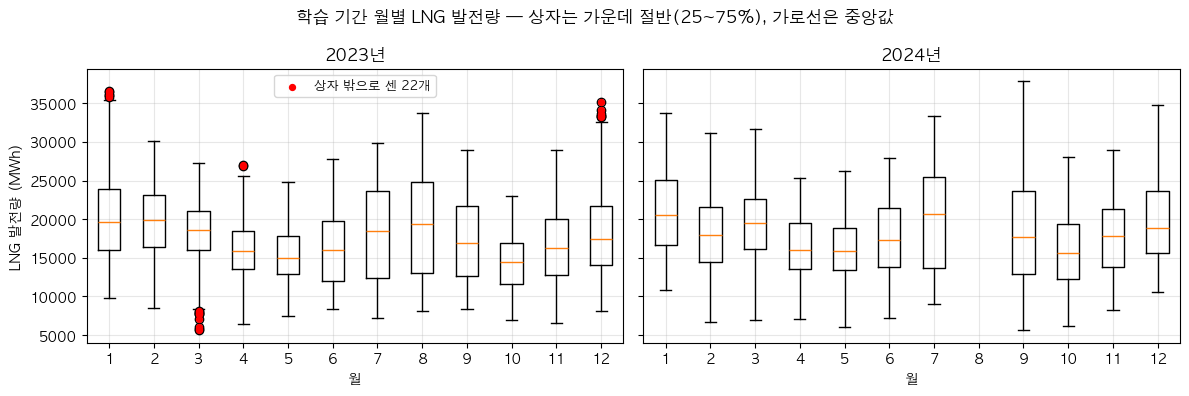

2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.


In [111]:
# 3단계 정제 · 3-라
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)       # 두 해를 나란히, 세로축은 같은 자로
for k, y in enumerate(학습해):
    g = train[train["year"] == y]                                # 학습 기간에서 그 해만
    자료 = [g.loc[g["month"] == m, "lng_mwh"].values for m in range(1, 13)]   # 달마다 값 묶음
    있는달 = [m for m in range(1, 13) if len(자료[m - 1]) > 0]     # 값이 있는 달만 (2024년 8월은 비어 있다)
    ax[k].boxplot([자료[m - 1] for m in 있는달], positions=있는달)  # 달마다 상자 하나
    ax[k].set_xticks(range(1, 13)); ax[k].set_xticklabels(range(1, 13))       # 가로축을 1~12월로
    ax[k].set_title(f"{y}년"); ax[k].set_xlabel("월"); ax[k].grid(alpha=.3)
    점 = 밖[밖["year"] == y]                                      # 그 해의 상자 밖 시각 (3-가에서 만든 표)
    if len(점):
        ax[k].scatter(점["month"], 점["lng_mwh"], color="red", zorder=3, s=18,
                      label="상자 밖으로 센 22개")
        ax[k].legend(loc="upper center", fontsize=9)
ax[0].set_ylabel("LNG 발전량 (MWh)")
plt.suptitle("학습 기간 월별 LNG 발전량 — 상자는 가운데 절반(25~75%), 가로선은 중앙값")
plt.tight_layout(); plt.show()

print("2024년 8월은 상자가 없습니다 — 물음 1에서 뺐기 때문입니다.")


### ✍️ 내 답변

이 그림에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 위에서 말한 것처럼 23년도에 몰려있다는 것 자체에서 경향성을 찾았는데 진짜 특이한건 3월에 아래에 찍히는데 4월에 맨 위에 찍힌건 뭐지?? 이거는 조금 살펴봐야겠는데?? 3월 날짜에서 어떤 날짜에 찍혔는지, 그리고 4월에 찍힌거 확인해가지고?? 4월 데이터 이상치는 한 번 더 봐야겠다. 예컨대 12,1월은 둘 다 많이 쓴 쪽이니까 경향이 같다고 말할 수 있는데 3월은 아래,, 4월도 날씨 비슷할 것 같은데 아래로 찍혀야하는거 아닌가?? 이건 살펴봐야겠는걸??

### 클로드 답변

> **짧게**
> 1. **제 셀의 표 제목이 틀렸습니다.** 3-나의 「[표 1] 아래로 벗어난 것 열 개」는 사실 「LNG가 적은 순서 열 개」였습니다. 아래로 벗어난 것은 아홉 개뿐이라 열 번째에 **위로 벗어난** 4월 18일이 딸려 들어왔습니다. 그림을 보고 찾아내신 것이 맞습니다.
> 2. 방향별로 세면 **아래 9개 · 위 13개**입니다. 4월 2개는 위입니다.
> 3. 「4월도 날씨 비슷한데 왜 위냐」의 답은 상자 자리가 달마다 다르기 때문입니다. 4월을 따로 볼 셀(`3-마`)을 붙였습니다.

**제가 틀린 것**

3-나를 `nsmallest(10)`으로 뽑으면서 표 제목을 「아래로 벗어난 것 열 개」라고 붙였습니다. 실제로 아래로 벗어난 것은 아홉 개이고, 열 번째 줄(2023-04-18 09:00, 26,849 MWh)은 위로 벗어난 것입니다. 값이 작은 순서로 열 개를 뽑았을 뿐인데 제목에 방향을 적어 버렸습니다. 셀을 고쳐서 **방향 칸을 표에 넣었습니다** — 다시 돌리시면 「아래」·「위」가 줄마다 찍힙니다.

**방향별로 세면 이렇습니다**

| 해·달 | 아래로 | 위로 | 그 달 상자 아래선 | 그 달 상자 위선 |
|---|---|---|---|---|
| 2023년 1월 | 0 | 5 | 4,335 | 35,592 |
| 2023년 3월 | 9 | 0 | 8,337 | 28,660 |
| 2023년 4월 | 0 | 2 | 6,064 | 25,955 |
| 2023년 12월 | 0 | 6 | 2,646 | 33,046 |

**「4월도 날씨 비슷할 것 같은데 아래로 찍혀야 하는 거 아닌가」에 대해**

상자의 자리가 달마다 다르기 때문입니다. 상자 밖은 그 달 안에서만 따집니다. 4월의 위선은 25,955이고 3월의 위선은 28,660입니다. 4월 18일 9시의 26,849는 4월 기준으로는 위선을 넘지만, 3월에 그 값이 나왔다면 상자 안에 들어갑니다. 4월은 난방이 끝나 LNG가 전체적으로 낮게 깔려 있어서 상자가 아래로 내려가 있고, 그래서 평범해 보이는 값도 위로 튀어나옵니다.

그러니 **「3월은 아래, 4월도 아래여야 한다」는 생각이 어긋난 이유는 날씨가 아니라 자를 그 달 안에서만 대기 때문입니다.** 이것이 달마다 따로 계산하는 방식의 약점이기도 합니다 — 4월의 26,849는 1월에 놓으면 한가운데 값입니다.

**4월 18일이 왜 높았는지는 `3-마`에서 보십니다.** 그날 하루를 시간별로 펴고 같은 달 평일 같은 시각 평균과 나란히 놓았습니다. 아래 새 셀입니다.

**그림에서 맞게 읽으신 것**

- 「23년도에 몰려 있다는 것 자체에서 경향성을 찾았다」 — 22개가 전부 2023년입니다. 다만 3-가 답 칸에 적었듯 이것은 2023년 기온이 유별났다는 뜻만은 아닙니다. 그 달의 값이 넓게 퍼져 있으면 상자도 넓어져서 웬만한 값은 밖으로 안 나갑니다. 12월과 1월이 위로 걸린 것은 기온이 낮았던 시각이 몇 개 있었기 때문이고, 그 달 전체가 유별났다면 오히려 상자가 넓어져 안 걸렸을 것입니다.
- 「12,1월은 둘 다 많이 쓴 쪽이니까 경향이 같다」 — 맞습니다. 표에서 1월 5개와 12월 6개가 전부 위입니다.

📘 **빅데이터분석기사 연결 — 2과목, 이상값 기준을 어느 범위에서 잡는가**

같은 1.5 사분위범위 규칙이라도 **어느 묶음 안에서 계산하느냐에 따라 걸리는 값이 달라집니다.** 여기서는 해·달마다 따로 계산했습니다. 만약 학습 기간 16,776시각을 한 덩어리로 놓고 계산했다면 4월 18일의 26,849는 아무 데도 안 걸립니다 — 전체로 보면 한가운데 값이기 때문입니다. 반대로 3월 26일의 5,631은 전체로 봐도 걸립니다.

**묶음을 나누는 쪽이 이 데이터에 맞습니다.** LNG는 달마다 수준이 크게 다르기 때문입니다. 전체로 한 번에 계산하면 여름과 겨울의 높은 값들만 걸리고, 봄가을 안에서 유난히 낮았던 시각은 하나도 안 걸립니다. 다만 그 대가가 지금 보신 것입니다 — 4월의 평범해 보이는 값이 위로 걸리는 일이 생깁니다.

교재에서 이상값 기준을 잡을 때 「전체로 볼지 집단별로 볼지」를 먼저 정하라고 하는 이유가 이것입니다. 어느 쪽이 맞다기보다 무엇을 찾으려는지에 달려 있습니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 4분위 자체에서 벗어났다는 것 자체가 데이터가 잘못됐다는 것을 의미하지 않는다. 좋아. 이해했어

## 3-마

**어디서 나온 셀인가.** 2026-09-19에 `3-라` 그림을 보시고 「3월에 아래에 찍히는데 4월에 맨 위에 찍힌 건 뭐지? 4월 데이터 이상치는 한 번 더 봐야겠다」고 하셔서 만들었습니다.

**무엇을 보는 셀인가.** 상자 밖으로 걸린 4월 2개가 2023년 4월 18일 9시와 10시입니다. 그날 하루를 0시부터 23시까지 펴고, 같은 달 평일 같은 시각의 평균을 옆에 놓고, 그 차이를 적었습니다. 기온과 원자력도 같이 놓았습니다. 그 두 시각만 튄 것인지 하루 종일 높았던 것인지 보는 셀입니다.

**2026-09-19에 고친 것 둘.** 처음에는 「4월 평일 평균」과 비교했는데, 상자그림의 가로선이 평균이 아니라 중앙값이라는 지적을 받고 중앙값으로 바꿨습니다. 그리고 「상자밖」 칸을 넣어 어느 시각이 실제로 상자 밖으로 걸렸는지 표 안에서 보이게 했습니다.


In [112]:
# 3단계 정제 · 3-마
하루 = train[(train["ts"] >= "2023-04-18") & (train["ts"] < "2023-04-19")].copy()   # 그날 24시각
평일 = train[(train["year"] == 2023) & (train["month"] == 4) & (train["is_weekend"] == 0)]  # 같은 달 평일 전부
중앙 = 평일.groupby("hour24")["lng_mwh"].median()                # 시각마다 4월 평일 중앙값
하루["시각별 중앙값"] = 하루["hour24"].map(중앙).round(0)          # 그 중앙값을 그날 옆에 붙인다
하루["차이"] = (하루["lng_mwh"] - 하루["시각별 중앙값"]).round(0)   # 그날이 중앙값보다 얼마나 많았나
아래선, 위선 = 경계[(2023, 4)]                                   # 3-나에서 만든 그 달의 상자 위아래 선
하루["상자밖"] = ["예" if (v < 아래선 or v > 위선) else "" for v in 하루["lng_mwh"]]
표 = 하루[["hour24", "lng_mwh", "시각별 중앙값", "차이", "상자밖", "ta"]]
표.columns = ["시", "4/18 LNG", "시각별 중앙값", "차이", "상자밖", "기온"]

print(f"2023년 4월 상자의 위선은 {위선:,.0f} MWh입니다. 이 선을 넘은 시각에만 「상자밖」이 붙습니다.")
print("표의 「차이」는 다른 기준입니다 — 같은 달 평일 같은 시각의 중앙값과 비교한 것입니다.\n")
print(표.to_string(index=False))


2023년 4월 상자의 위선은 25,955 MWh입니다. 이 선을 넘은 시각에만 「상자밖」이 붙습니다.
표의 「차이」는 다른 기준입니다 — 같은 달 평일 같은 시각의 중앙값과 비교한 것입니다.

 시  4/18 LNG  시각별 중앙값    차이 상자밖  기온
  0   15327.0        14479.0   848.0         14.8
  1   13972.0        13120.0   852.0         14.6
  2   13838.0        12906.0   932.0         14.6
  3   13951.0        12759.0  1192.0         14.6
  4   14291.0        13118.0  1173.0         14.5
  5   15545.0        13984.0  1561.0         14.0
  6   17826.0        15686.0  2140.0         13.5
  7   20332.0        17168.0  3164.0         12.0
  8   24253.0        17402.0  6851.0         10.8
  9   26849.0        17254.0  9595.0     예  10.7
 10   27031.0        16612.0 10419.0     예  10.8
 11   25251.0        15688.0  9563.0         11.1
 12   22560.0        15110.0  7450.0         11.5
 13   23339.0        15992.0  7347.0         12.9
 14   22919.0        16896.0  6023.0         14.4
 15   23134.0        18055.0  5079.0         16.7
 16   22921.0        19548.0  3373.0         18.0
 17   2

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 보니까 차이가 더 클때? 안ㅈ 찍힌 것도 있다. 즉 평균에서 떨어져 나와서 찍힌 것. 그러니 3월에 아래 찍히고, 4월 위에 찍혀서 문제가 있다는 생각 자체가 잘못되었다. 그냥 그렇게 찍힌 것. 데이터 이상은 아니라고 판단할 수 있을 것 같다. 다만 내가 알기로 상자그림의 중앙값은 평균이 아니라 중앙값 아닌가?? 그리고 평균과 차이가 클 때 즉, 9,10시에 찍힌 건 이해했는데 차이 자체는 다른 시간이 큰데 그러면 아니 뭐지 평균 자체가 다르게 찍힌건가?? 셀 자체의 글자와 이거 위치가 달라서 헷갈려 

### 클로드 답변

> **짧게**
> 1. **열이 어긋난 것은 제 잘못입니다.** 한글 열 이름을 두 칸으로 세는 옵션을 안 걸어서 머리글과 숫자가 밀렸습니다. 준비 ①에 옵션을 넣었습니다 — **준비 ①부터 다시 돌리시면 모든 표의 줄이 맞습니다.**
> 2. **「상자그림의 가로선은 평균이 아니라 중앙값 아닌가」 — 맞습니다.** 제가 평균으로 비교했습니다. 중앙값으로 바꿨습니다.
> 3. **「차이가 더 클 때 안 찍힌 것도 있다」 — 정확히 보셨습니다.** 그 이유가 아래에 있습니다.

**맞게 읽으신 것**

- **「3월에 아래 찍히고 4월에 위에 찍혀서 문제가 있다는 생각 자체가 잘못되었다. 그냥 그렇게 찍힌 것」** — 맞습니다. 상자 밖은 그 달 안에서만 따지는 판정이고, 달마다 상자 자리가 다릅니다.
- **「상자그림의 중앙값은 평균이 아니라 중앙값 아닌가」** — 맞습니다. 상자그림의 가로선은 중앙값이고 상자의 위아래 끝은 1사분위수·3사분위수입니다. 평균은 상자그림에 나오지 않습니다. 제가 3-마를 평균으로 만든 것이 앞뒤가 안 맞았습니다. 중앙값으로 고쳤습니다.

**「차이 자체는 다른 시간이 큰데 왜 9·10시만 찍혔나」**

**두 개가 서로 다른 기준이기 때문입니다.** 상자 밖 판정은 그 달의 값 전체를 한 줄로 늘어놓고 위아래 선을 긋습니다. 시각을 구분하지 않습니다. 2023년 4월의 위선은 25,955 MWh이고, 그 선을 넘은 것은 9시(26,849)와 10시(27,031) 둘뿐입니다.

표의 「차이」는 다른 것을 봅니다. 같은 달 평일 같은 시각의 중앙값과 비교한 값입니다. 11시는 차이가 9,563으로 9시(9,595)와 거의 같지만, 4월 11시의 보통 수준이 원래 낮아서(중앙값 15,688) 25,251까지 올라가도 위선을 안 넘습니다. 8시도 차이가 6,851인데 값 자체는 24,253이라 안 걸립니다.

**그래서 무엇이 달라지나.** 「상자 밖 22개」는 그 달에서 값이 큰 쪽·작은 쪽 끝에 있던 시각들이지, 「그 시각치고 유난했던 시각」이 아닙니다. 둘은 다른 질문이고 답도 다릅니다. 4월 18일은 새벽부터 낮까지 하루 종일 그 시각 중앙값보다 높았는데, 상자 밖으로 걸린 것은 값이 가장 컸던 두 시각뿐입니다.

**4월 18일이 왜 그랬는지는 이 데이터로 확인되지 않습니다.** 확인되는 것은 그날 아침 기온이 10.7도로 그 시간대치고 낮았고, 원자력은 하루 내내 16,918~16,932로 거의 일정했다는 것입니다. 원전이 갑자기 선 것도 아닙니다. 그러니 「확인 불가」로 두고 넘어갑니다. 22개를 남기기로 하셨으니 이 시각도 학습에 들어가고, 모델이 이런 날을 얼마나 틀리는지는 7단계에서 봅니다.

📘 **빅데이터분석기사 연결 — 2과목, 평균과 중앙값 그리고 판정 기준의 범위**

**상자그림이 중앙값과 사분위수로 그려지는 이유**는 극단값에 덜 흔들리기 때문입니다. 평균은 아주 큰 값 하나가 끼면 통째로 끌려 올라갑니다. 중앙값은 순서만 보므로 그 하나가 얼마나 큰지와 상관없이 가운데에 머뭅니다. 이상값을 찾는 도구가 이상값에 흔들리면 안 되니 중앙값 계열로 그립니다. 창주 님이 4단계 개념 표에 「Mean이 평균이고 median이 중앙값이지」라고 적으신 그 구분이 여기서 쓰입니다.

**판정 기준을 어느 범위에서 잡느냐**도 같이 봐야 합니다. 지금은 해·달 단위로 잡았습니다. 만약 해·달·시각 단위로 더 잘게 잡았다면 4월 18일은 9·10시가 아니라 새벽부터 낮까지 여러 시각이 걸렸을 것입니다. 잘게 나눌수록 「그 조건치고 유난한 값」을 찾게 되고, 넓게 잡을수록 「그냥 큰 값」을 찾게 됩니다. 어느 쪽이 맞다기보다 무엇을 찾으려는지에 달려 있습니다.

### ✍️ 읽고 나서

클로드 답변을 읽고 더 적을 것이 있으면 여기 적습니다. 없으면 비워 두셔도 됩니다.

답: 좋아. 그러면 22개의 데이터는 큰 문제가 없으니 그냥 진행해도 될 것 같어.

# ✍️ 3단계를 닫으며

물음 셋입니다. 각 물음 아래 「답:」에 적으시면 됩니다.

*2026-09-19에 창주 님이 채팅으로 답하시고 「너가 보고 채워줘」라고 하셔서 제가 옮겨 적었습니다. 1번은 위 칸들에서 정하신 것을 모은 것이고, 2·3번은 채팅에서 하신 말을 다듬은 것입니다. 고치실 것이 있으면 그 자리에서 고치시면 됩니다.*

---

#### 1. 3단계에서 정한 것을 한 문단으로 적으면 어떻게 됩니까?

- 재료: 위에서 정하신 둘(2024년 8월과 2026년 5월 / 상자 밖 점 22개)과, 물음 2에서 확인만 한 태양광 설비용량.
- 이 문단이 README 한계와 11단계 결론에 그대로 들어갑니다.

답: 뺀 것이 셋이다. 2024년 2월 29일은 API에 그날이 아예 없어서 09-12에 빼기로 했다. 2024년 8월 1일부터 31일까지는 API 기록이 잘못 들어 있어서 학습에서 뺐다 — 다시 요청해도 같은 값이 왔고 EPSIS 월별 표에는 그 달이 정상으로 들어 있으니 실제 발전이 아니라 기록의 문제다. 2026년 5월 2일부터 17일까지는 9단계에서 예측과 비교할 때 뺀다. 비교할 실제값이 없기 때문이다.

남긴 것은 상자 밖 22개다. 값이 잘못 들어온 것이 아니라 조건이 극단적이었던 시각이다. 아래로 벗어난 아홉 개는 2023년 3월 일요일 낮이고 기온이 10~15도라 난방도 냉방도 필요 없던 때이며, 위로 벗어난 열세 개는 1월·4월·12월의 평일이고 대부분 한겨울 아침이다. 그래서 빼지 않고 학습에 남긴다.

태양광 설비용량은 값 자체에 빈 칸도 잘못된 값도 없어 3단계에서 할 일이 없었다. 다만 학습(2023·2024년)과 채점(2025년)에서 값이 한 번도 겹치지 않는 것을 확인했고, **설비용량 대신 태양광 발전량을 쓰는 쪽으로 방향을 정했다.** LNG와 원자력은 발전량인데 태양광만 설비용량이라 같은 것을 재고 있지 않았기 때문이다. 발전량으로 바꾸면 학습 밖이 100%에서 0.3%로 떨어진다. 확정은 6단계에서 한다.


#### 2. 이번에 뺀 것 때문에 나중에 무엇을 조심해야 합니까?

답: 2024년 8월 데이터가 없으니 8월은 2023년 한 해치만 배우게 된다. 7단계에서 달별 오차를 볼 때 8월은 따로 떼어 보거나, 아예 보지 않고 한계를 명확히 적고 진행해야 한다.


#### 3. 다음은 4단계 탐색적 분석입니다. 무엇을 다시 보고 싶습니까?

답: 지금은 따로 생각나는 것이 없다. 4단계에 해당하는 내용도 2·3단계에서 이미 한 것 같고, 데이터가 널리 퍼져 있어서 무엇을 적어야 할지 모르겠다. 진행하면서 궁금한 것이 떠오르지 않을까 싶다.

*(2026-09-19에 이 칸을 적은 뒤 채팅에서 둘이 나왔습니다. 클로드가 덧붙여 적습니다.)*

- **태양광 발전량과 LNG의 시간대별 관계를 다시 본다.** 09-13에 4단계에서 「2025년 평일 낮 시간 LNG가 2023년보다 줄었는데 태양광 설비용량이 28% 는 것이 원인으로 보인다(미확인)」고 적었다. 설비용량은 밤에도 낮과 같은 값이라 시간대 이야기에 맞지 않았다. 발전량으로 바꾸면 낮에만 올라가므로 맞춰 볼 수 있다.
- **석탄이 LNG보다 먼저 움직이는지 시차를 두고 확인한다.** 2단계 월별 그림 칸에 「녹색 선이 그림을 그리면 파란 선이 따라가는 느낌을 받는데? 이런건 정확하진 않은 표현인 것 같다」고 적었다. 월별 그림으로는 둘 다 계절을 따라가므로 순서를 볼 수 없다. 시간별 석탄과 LNG를 시차를 두고 맞춰 봐야 한다. **만약 석탄이 먼저 움직인다면 화살표가 한 방향이 되고, 시차를 둔 석탄은 뺄셈이 아니라 정당한 입력이 될 수 있다.** 지금 석탄을 입력에서 뺀 근거가 「같은 시각에 서로 밀고 당긴다」였으므로, 이 확인은 그 근거를 다시 보는 일이다.


---

*정한 것을 표에 반영하고 그 표를 `data/hot/`에 저장하는 셀은 이 아래에 있습니다.*

### 클로드 답변 — 3단계를 닫으며

> **짧게**
> 1. 날짜 하나 정정했습니다 — 2026년 5월은 **2일부터 17일까지**입니다(4일이 아니라 2일).
> 2. 3단계에서 정한 것은 넷입니다. 위 칸에 모아 적었습니다.
> 3. 4단계에서 다시 볼 것이 이 대화에서 하나 생겼습니다. 아래에 적습니다.

**날짜 정정**

「26년 5월도 4~17?인가」라고 하셨는데 **5월 2일부터 17일까지 열엿새**입니다. 1-다에서 보신 표가 그것입니다 — 5월 1일은 192행으로 정상이고, 2일이 120행(LNG 하루 합 1,047), 3일부터 16일까지가 48행(LNG 없음), 17일이 0행입니다. 18일부터 다시 정상입니다.

**「진행하면서 궁금한 것이 떠오르지 않을까」 — 그 방식이 맞습니다. 다만 이 대화에서 하나는 이미 생겼습니다.**

**태양광을 설비용량에서 발전량으로 바꾸기로 하셨으니, 4단계에서 본 숫자 하나가 달라집니다.** 09-13에 4단계에서 「2025년 평일 낮 시간 LNG가 2023년보다 줄고 저녁에 늘었는데, 태양광 설비용량이 28% 는 것이 원인으로 보인다(미확인)」고 적으셨습니다. 그때는 설비용량으로 본 것이고, 설비용량은 밤에도 낮과 같은 값이라 시간대별 이야기를 하기에 맞지 않습니다. 발전량으로 다시 보면 낮에만 올라가고 밤에는 0이므로 「낮 시간 LNG가 준 것」과 곧바로 맞춰 볼 수 있습니다.

그러니 4단계를 열 때 이것 하나는 적어 두고 시작하시면 됩니다 — **「태양광 발전량과 LNG의 시간대별 관계를 다시 본다. 4단계에서 미확인으로 남긴 원인을 확인할 수 있는지.」** 나머지는 말씀하신 대로 진행하면서 떠오르는 것을 적으면 됩니다.

**4단계가 2·3단계와 겹쳐 보이는 것에 대해**

맞습니다. 그리고 그것이 정상입니다. 09-19에 창주 님이 「2단계에서 한 것이 3·4단계에도 걸쳐 있는 것 아니냐」고 물으셨고, 그때 정한 것이 **단계는 데이터를 나누는 것이 아니라 「무엇을 정하느냐」를 나눈다**는 것이었습니다. 같은 표가 여러 단계에 나오는 것은 문제가 아니고, 같은 결정을 두 번 하는 것이 문제입니다.

4단계에서 정하는 것은 **입력 후보 목록**입니다. 무엇이 LNG를 움직이는지 보고 「이 열들을 후보로 남긴다」를 정합니다. 09-13에 이미 「입력 후보 여덟을 다 남긴다」로 정하셨으니, 4단계에서 남은 일은 그 판단이 지금도 맞는지 보고 닫는 칸을 적는 것입니다. 태양광 열이 바뀌었으니 후보 목록도 한 줄 바뀝니다.

📘 **빅데이터분석기사 연결 — 1과목, 분석 절차를 되돌아가는 것**

교재의 분석 절차는 1단계부터 11단계까지 한 줄로 그려져 있지만, 실제로는 뒤 단계에서 앞 단계로 돌아가는 화살표가 여러 개 있습니다. 이 프로젝트에서만 벌써 셋이 일어났습니다. 4단계를 3단계보다 먼저 했고(상자 밖 점이 거기서 나와 3단계 물음이 되었습니다), 3단계에서 6단계 결정을 미뤘고, 오늘은 3단계를 하다 태양광 열 자체를 바꾸기로 해서 4단계 숫자가 달라졌습니다.

**되돌아가는 것이 절차의 실패가 아니라 절차의 일부입니다.** 중요한 것은 되돌아간 것을 기록에 남기는 일입니다. README의 「걸어온 자취」가 그 기록이고, 오늘 것도 거기 한 줄 적었습니다.

## 저장 — 다음 단계가 읽을 표

**어디서 나온 셀인가.** 3단계에서 정한 것을 표에 반영해 파일로 남기는 셀입니다. 5·6·7단계 노트북은 이 파일을 읽습니다. 그래야 단계마다 원자료를 다시 읽고 붙이는 일을 되풀이하지 않고, 3단계에서 정한 것이 뒷단계에 그대로 이어집니다.

**무엇이 들어가나.** 2023·2024·2025년 시간별 표입니다. 2024년 2월 29일과 8월 한 달은 준비 ②에서 이미 빠져 있습니다. 상자 밖 22개는 남기기로 하셨으므로 그대로 들어갑니다. **태양광은 설비용량(`solar_cap_mw`)과 발전량(`solar_mwh`)을 둘 다 넣습니다** — 어느 쪽을 쓸지는 6단계에서 정하므로 둘 다 있어야 그때 비교할 수 있습니다.

**2026년은 여기 없습니다.** 적용 구간이라 9단계에서 씁니다. 그때 같은 방식으로 만들고, 5월 2일부터 17일까지를 빼는 것은 이 노트북 닫는 칸에 적어 두었습니다.

In [113]:
# 3단계 정제 · 저장
hot = os.path.join(ROOT, "data", "hot")                          # 단계 사이를 잇는 폴더
os.makedirs(hot, exist_ok=True)                                  # 없으면 만든다

태 = pd.concat([pick(load_kpx(y), "태양광", "mwh", "solar_mwh")   # 태양광 발전량도 같이 저장한다
                for y in (2023, 2024, 2025)])                    # 어느 쪽을 쓸지는 6단계에서 정한다
저장 = tbl.merge(태, on="ts", how="left")

경로 = os.path.join(hot, "clean_2023_2024_2025.csv")
저장.to_csv(경로, index=False, encoding="utf-8-sig")
print("저장했습니다 →", os.path.relpath(경로, ROOT))
print(f"  {len(저장):,}행 · 열 {len(저장.columns)}개")
for i in range(0, len(저장.columns), 5):                          # 열 이름을 다섯 개씩 끊어 찍는다
    print("   ", ", ".join(저장.columns[i:i + 5]))

print("\n해별 행 수 — 2024년이 8,016인 것은 2월 29일과 8월 한 달을 뺐기 때문입니다")
print(저장.groupby("year").size().rename("행 수").to_string())
print("\n빈 칸이 있는 열")
print(저장.isna().sum()[lambda s: s > 0].to_string() if 저장.isna().sum().sum() else "  없음")


저장했습니다 → data/hot/clean_2023_2024_2025.csv
  25,536행 · 열 13개
    ts, lng_mwh, nuke_mwh, solar_cap_mw, ta
    hm, icsr, year, month, hour24
    dow, is_weekend, solar_mwh

해별 행 수 — 2024년이 8,016인 것은 2월 29일과 8월 한 달을 뺐기 때문입니다
year
2023    8760
2024    8016
2025    8760

빈 칸이 있는 열
  없음


# 이 프로젝트에서 쓴 개념

*단계마다 📘가 나오면 한 줄씩 붙인다. 「내 말로」는 단계를 닫을 때 **칸을 안 보고 말로 설명한 문장**을 적는 칸이다. 클로드 설명과 나란히 놓으면 차이가 보인다.*

| 개념 | 빅분기 · 어디서 | 클로드 설명 | ✍️ 내 말로 |
|---|---|---|---|
| 결측을 채울지 뺄지 | 2과목 데이터 정제 (3단계 물음 1) | 흩어져 빠졌으면 앞뒤 값이나 비슷한 조건의 평균으로 채운다. 한 달이 통째로 잘못되어 있으면 채울 근거가 그 안에 없어서 행째로 뺀다. 평균으로 채우면 「8월은 평균이었다」는 없던 사실을 만들어 넣게 된다 |  24년 8월은 값이 다른 날과 너무 벗어나고 연료 종류도 부족해서 뺐고, 23년 상자 밖 점들은 192행이 다 온 정상 데이터라 다시 살펴보고 남겼다. 셀 자체의 형태가 서로 맞아떨어지는지 본 다음에 방향을 정하는 것 |
| 이상값 판정과 처리는 다른 일 | 2과목 이상값 (3단계 물음 3) | 판정은 규칙이 한다(1사분위수 − 1.5 사분위범위 아래, 3사분위수 + 1.5 위). 처리는 사람이 원인을 붙여 정한다. 값이 잘못 들어온 것이면 빼고, 조건이 극단적이었던 것이면 남긴다 |  상자가 점을 찍는 건 어떤 기준으로 묶은 것에서 일반적인 범위 안에 있는지 아닌지를 뜻한다. 범위를 벗어난다고 이상치로 기록될 수는 있지만 잘못 측정되었다고 말할 수는 없다. 이건 세부적으로 살펴서 결정해야 할 부분이다 |
| 판정 기준을 어느 범위에서 잡는가 | 2과목 이상값 (3단계 3-라·3-마) | 같은 1.5 사분위범위 규칙도 해·달 단위로 잡느냐 전체로 잡느냐에 따라 걸리는 값이 달라진다. 4월 18일의 26,849는 4월 기준으로는 밖이고 1월 기준으로는 한가운데다 |  묶음마다 중앙값과 사분위수의 위치가 조금씩 다르니까 |
| 평균과 중앙값 | 2과목 기초통계 (3단계 3-마) | 상자그림의 가로선은 중앙값이고 상자 끝은 사분위수다. 평균은 큰 값 하나에 끌려가지만 중앙값은 순서만 보므로 안 흔들린다. 이상값을 찾는 도구가 이상값에 흔들리면 안 되니 중앙값 계열로 그린다 |  상자그림의 가로선은 중앙값이다. 상자그림은 이상치를 탐지하는 것이라 이럴 경우 적합한 건 중앙값이지 평균이 아니다 |
| 학습 범위 밖의 값 | 4과목 예측 (3단계 물음 2) | 모델이 배운 적 없는 범위의 값을 만나 답을 내는 것. 선형회귀는 기울기를 이어서 답하고, 트리 계열은 가장 끝 칸의 답을 그대로 낸다. 태양광 설비용량이 100%였고 발전량으로 바꾸니 0.3%가 되었다 |  모델링을 하려면 학습에 쓴 것과 예측할 때 만나는 것이 유사해야 하는데, 완전히 다르면 공통점을 찾아 예측한다는 모델링 자체가 성립하지 않을 수 있다 |
| 모델 밖에서 정해지는 입력 | 2과목 변수 (3단계 2-다) | 기온·원자력·태양광처럼 LNG와 상관없이 정해지는 값. 왜 그 값이 되었는지는 모델이 몰라도 된다. 석탄과 총수요는 LNG와 서로 밀고 당기므로 넣으면 뺄셈이 된다 |  원자력은 안정적으로 수급하는 원처럼 기본을 받쳐 주는 느낌이고, 변화할 때는 LNG와 석탄이 요동치면서 수요에 맞게 쓰인다. 그러니 LNG가 줄면 석탄이 늘고 반대도 성립한다 |
